
# Data-Driven Maintenance Prioritisation using Machine Performance and Health Data

Code notebook for the MSc Data Science thesis. It uses the public AI4I 2020 dataset to predict machine failure, explain the predictions, and turn the predicted risk into a list of machines to inspect first.


## Problem Statement

Machine manufacturing maintenance teams often have limited capacity to inspect machines.
Although machine-health data can be used to predict failure risk, a prediction alone
does not show which machines should be inspected first when only a limited number
of inspections is possible.

This project uses machine performance and health data to identify and rank machines
according to predicted failure risk. It evaluates whether the highest-risk cases contain
a high proportion of actual failures under fixed inspection capacities.

## Load the Libraries and Data set
The AI4I 2020 dataset has 10,000 rows. Each row is one machine run, with its operating conditions and whether it failed.

The data is downloaded from Kaggle with `kagglehub` (no login needed).

In [3]:
import os
import numpy as np
import pandas as pd
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from xgboost import XGBClassifier
import time
from sklearn.model_selection import RandomizedSearchCV



In [4]:
# Save all outputs to Google Drive so nothing is lost when Colab disconnects
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT_DIR = "/content/drive/MyDrive/thesis_maintenance"
os.makedirs(f"{PROJECT_DIR}/outputs", exist_ok=True)
os.chdir(PROJECT_DIR)
print("Working folder:", os.getcwd())

Mounted at /content/drive
Working folder: /content/drive/MyDrive/thesis_maintenance


In [5]:


try:
    folder = kagglehub.dataset_download("stephanmatzka/predictive-maintenance-dataset-ai4i-2020")
    csv_name = [f for f in os.listdir(folder) if f.endswith(".csv")][0]
    df = pd.read_csv(os.path.join(folder, csv_name))
except ImportError:
    df = pd.read_csv("data/ai4i2020.csv")

print("Rows and columns:", df.shape)
print("Missing values  :", df.isnull().sum().sum())
print("Duplicate rows  :", df.duplicated().sum())
df.head()

100%|██████████| 136k/136k [00:00<00:00, 42.2MB/s]

Extracting files...
Rows and columns: (10000, 14)
Missing values  : 0
Duplicate rows  : 0


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## 2. Target Variable and Failure Structure

This section looks at the target column, `Machine failure`, before any modelling.

- **Imbalance:** only 339 of 10,000 runs failed (3.39%). A model that always predicts "no failure" would already be 96.6% accurate, so accuracy alone is misleading.
- **Failure modes:** the five columns TWF, HDF, PWF, OSF and RNF record *how* a machine failed. They are part of the outcome, so they are never used as model inputs (that would be target leakage).
- **Consistency check:** in 9 rows the machine failed with no mode recorded, and in 18 rows a mode is recorded but the machine did not fail. These come from the original data and are left unchanged.
- **Product type:** low-quality (L) products fail most often (3.92%), high-quality (H) products least often (2.09%).

In [6]:
# Failure vs non-failure
target = df["Machine failure"]
summary = pd.DataFrame({
    "Count": target.value_counts().sort_index(),
    "Percentage (%)": (target.value_counts(normalize=True).sort_index() * 100).round(2),
}).rename(index={0: "No failure (0)", 1: "Failure (1)"})
print("1. Machine failure distribution")
display(summary)
print(f"\nImbalance ratio: {summary.iloc[0, 0] / summary.iloc[1, 0]:.2f} non-failures for every failure")

# How often each failure mode occurs
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_summary = pd.DataFrame({"Count": df[failure_modes].sum()})
mode_summary["Percentage of data (%)"] = (mode_summary["Count"] / len(df) * 100).round(2)
print("\n2. Failure modes")
display(mode_summary)

# How many failure modes are active in each row
modes_per_row = df[failure_modes].sum(axis=1)
print("\n3. Number of active failure modes per row")
display(modes_per_row.value_counts().sort_index().rename_axis("Active modes").to_frame("Rows"))

# Do the failure modes agree with the Machine failure label?
print("\n4. Consistency check")
print("Failure = 1 but no failure mode :", ((target == 1) & (modes_per_row == 0)).sum())
print("Failure = 0 but a failure mode  :", ((target == 0) & (modes_per_row > 0)).sum())
print("\nRows where each mode is 1, split by Machine failure:")
display(pd.DataFrame({mode: df.loc[df[mode] == 1, "Machine failure"].value_counts().reindex([0, 1], fill_value=0)
                      for mode in failure_modes}).T.rename(columns={0: "Failure = 0", 1: "Failure = 1"}))

# Product type: share of data and failure rate
type_summary = df.groupby("Type").agg(Rows=("Machine failure", "size"), Failures=("Machine failure", "sum"))
type_summary["Share of data (%)"] = (type_summary["Rows"] / len(df) * 100).round(2)
type_summary["Failure rate (%)"] = (type_summary["Failures"] / type_summary["Rows"] * 100).round(2)
print("\n5. Product type")
display(type_summary.loc[["L", "M", "H"]])

1. Machine failure distribution


,Count,Percentage (%)
Machine failure,,
No failure (0),9661,96.61
Failure (1),339,3.39



Imbalance ratio: 28.50 non-failures for every failure

2. Failure modes


,Count,Percentage of data (%)
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19



3. Number of active failure modes per row


,Rows
Active modes,
0,9652
1,324
2,23
3,1



4. Consistency check
Failure = 1 but no failure mode : 9
Failure = 0 but a failure mode  : 18

Rows where each mode is 1, split by Machine failure:


Machine failure,Failure = 0,Failure = 1
TWF,0,46
HDF,0,115
PWF,0,95
OSF,0,98
RNF,18,1



5. Product type


,Rows,Failures,Share of data (%),Failure rate (%)
Type,,,,
L,6000,235,60.00,3.92
M,2997,83,29.97,2.77
H,1003,21,10.03,2.09


## ## 3. Feature Engineering and Exploratory Data Analysis

**Purpose:** to understand how failed and non-failed machine runs differ before any model is built. Two physically meaningful features are added, and the operating conditions of the two groups are compared with statistics, failure rates and plots. The results feed thesis Section 5.2 (Table 5.2) and explain why non-linear tree models are tested later.

### 3.1 Create the engineered features

Works on a copy of the data (`analysis_df`) so the raw data stays unchanged, and adds:
- **Temperature difference [K]** = process temperature − air temperature (a small gap can mean poor heat dissipation)
- **Power [W]** = torque × angular speed, where angular speed = 2π × rpm / 60

Both are calculated only from measurements available before a failure, so they do not leak the outcome.

In [7]:

# Work on a copy so the raw data stays untouched
analysis_df = df.copy()

analysis_df["Temperature difference [K]"] = analysis_df["Process temperature [K]"] - analysis_df["Air temperature [K]"]
analysis_df["Power [W]"] = analysis_df["Torque [Nm]"] * 2 * np.pi * analysis_df["Rotational speed [rpm]"] / 60

numeric_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
                    "Torque [Nm]", "Tool wear [min]", "Temperature difference [K]", "Power [W]"]

print("Analysis data:", analysis_df.shape)

Analysis data: (10000, 16)


### 3.2 Summary statistics and operating conditions by failure status

First the overall summary of each numeric variable, then the mean and median for failed vs non-failed runs (Table 5.2).

**What to look for:** failed runs have higher torque (50.17 vs 39.63 Nm), tool wear (143.78 vs 106.69 min) and power, and lower rotational speed and temperature difference. Rotational speed is strongly skewed (1.99) because of a few very fast runs.

In [8]:
# Overall summary statistics
stats = analysis_df[numeric_features].describe().T
stats["skewness"] = analysis_df[numeric_features].skew()
print("Summary statistics")
display(stats.round(2))

# Mean and median: failed vs non-failed runs (Table 5.2)
grouped = analysis_df.groupby("Machine failure")[numeric_features]
by_status = pd.DataFrame({
    "No-failure mean": grouped.mean().loc[0],
    "Failure mean": grouped.mean().loc[1],
    "No-failure median": grouped.median().loc[0],
    "Failure median": grouped.median().loc[1],
})
by_status["Mean difference (%)"] = (by_status["Failure mean"] / by_status["No-failure mean"] - 1) * 100
print("\nOperating conditions by failure status")
display(by_status.round(2))

Summary statistics


,count,mean,std,min,25%,50%,75%,max,skewness
Air temperature [K],10000.0,300.00,2.00,295.30,298.30,300.10,301.5,304.50,0.11
Process temperature [K],10000.0,310.01,1.48,305.70,308.80,310.10,311.1,313.80,0.02
Rotational speed [rpm],10000.0,1538.78,179.28,1168.00,1423.00,1503.00,1612.0,2886.00,1.99
Torque [Nm],10000.0,39.99,9.97,3.80,33.20,40.10,46.8,76.60,-0.01
Tool wear [min],10000.0,107.95,63.65,0.00,53.00,108.00,162.0,253.00,0.03
Temperature difference [K],10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10,-0.07
Power [W],10000.0,6279.74,1067.42,1148.44,5561.18,6271.03,7003.0,10469.92,0.01



Operating conditions by failure status


,No-failure mean,Failure mean,No-failure median,Failure median,Mean difference (%)
Air temperature [K],299.97,300.89,300.00,301.60,0.30
Process temperature [K],310.00,310.29,310.00,310.40,0.10
Rotational speed [rpm],1540.26,1496.49,1507.00,1365.00,-2.84
Torque [Nm],39.63,50.17,39.90,53.70,26.59
Tool wear [min],106.69,143.78,107.00,165.00,34.76
Temperature difference [K],10.02,9.40,9.80,9.30,-6.16
Power [W],6244.55,7282.82,6243.05,7611.43,16.63


### 3.3 Correlation and failure rate by quartile

Correlation shows how strongly each variable moves with failure; it describes association, not cause. The quartile table splits each variable into four equal-sized groups and shows the failure rate in each.

**What to look for:** risk sits at the extremes, not in a straight line. 10.15% of runs fail in the lowest-speed quartile, 9.87% in the highest-torque quartile, 6.93% in the highest tool-wear quartile and 8.92% in the highest-power quartile. This non-linear pattern is why tree-based models are compared with Logistic Regression later.

In [9]:
# Correlation with the target
print("Correlation with Machine failure")
display(analysis_df[numeric_features + ["Machine failure"]].corr()["Machine failure"]
        .drop("Machine failure").sort_values(ascending=False).round(4).to_frame("Correlation"))

# Failure rate (%) in each quartile of every variable
quartile_rates = pd.DataFrame({
    col: analysis_df.groupby(pd.qcut(analysis_df[col], 4, labels=["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"]),
                             observed=False)["Machine failure"].mean() * 100
    for col in numeric_features
}).T
print("\nFailure rate (%) by quartile")
display(quartile_rates.round(2))

Correlation with Machine failure


,Correlation
Torque [Nm],0.1913
Power [W],0.1760
Tool wear [min],0.1054
Air temperature [K],0.0826
Process temperature [K],0.0359
Rotational speed [rpm],-0.0442
Temperature difference [K],-0.1117



Failure rate (%) by quartile


,Q1 (lowest),Q2,Q3,Q4 (highest)
Air temperature [K],2.10,2.19,2.34,7.04
Process temperature [K],2.47,2.54,4.76,3.92
Rotational speed [rpm],10.15,0.96,0.48,1.93
Torque [Nm],1.91,0.56,1.32,9.87
Tool wear [min],2.17,2.36,2.10,6.93
Temperature difference [K],6.68,2.28,2.33,2.15
Power [W],1.96,0.88,1.80,8.92


### 3.4 Distribution plots and boxplots

Visual comparison of failed and non-failed runs for every numeric variable: histograms show the shape of each distribution, boxplots show the median, spread and outliers.

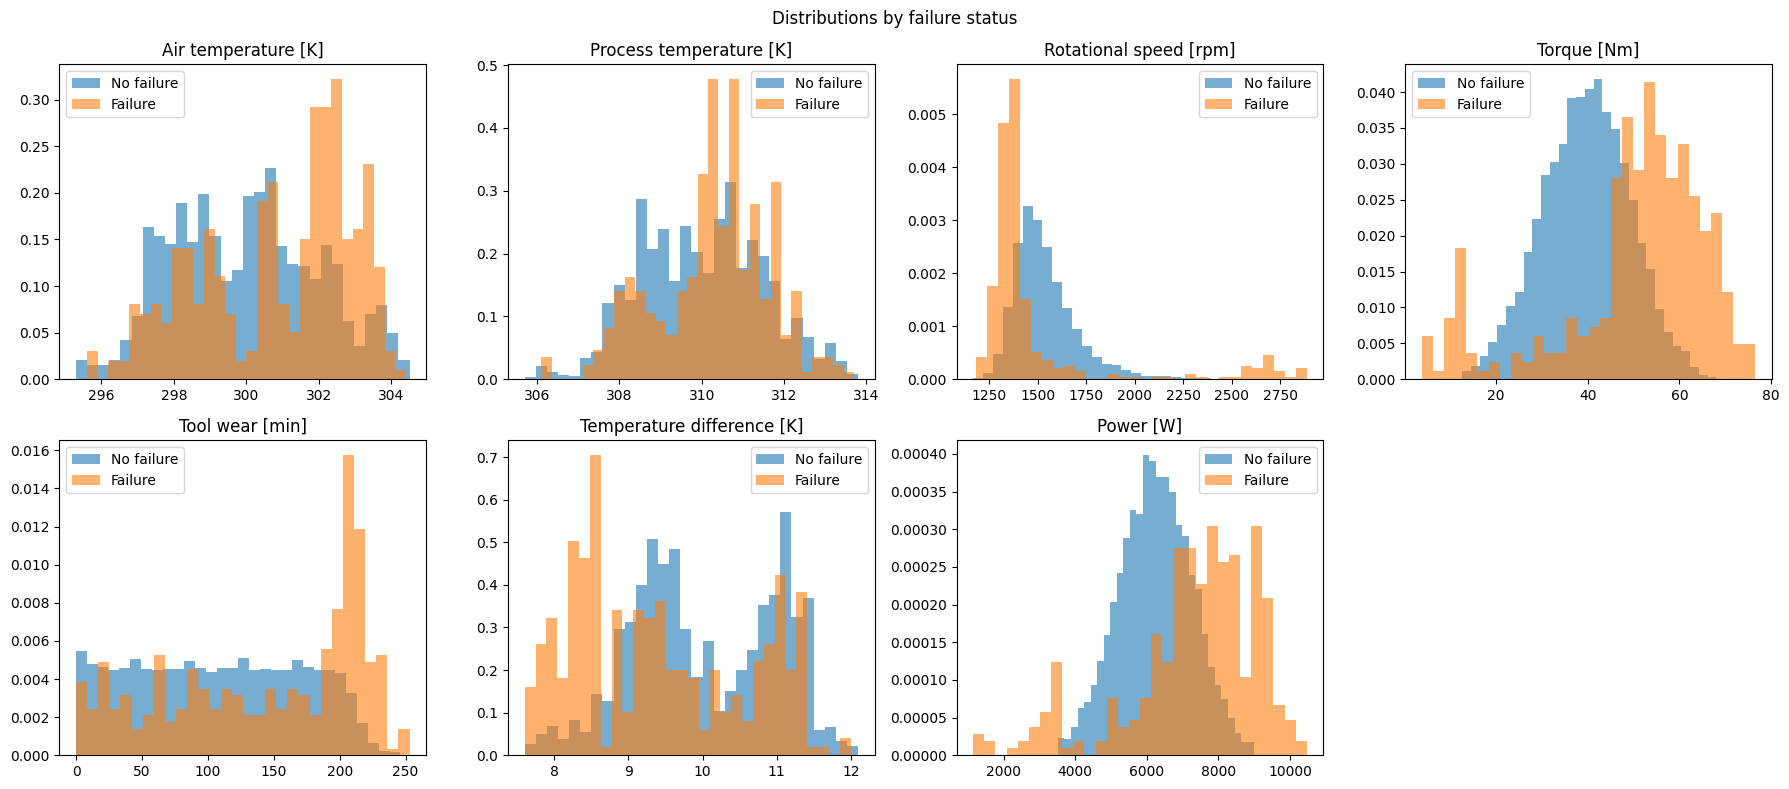

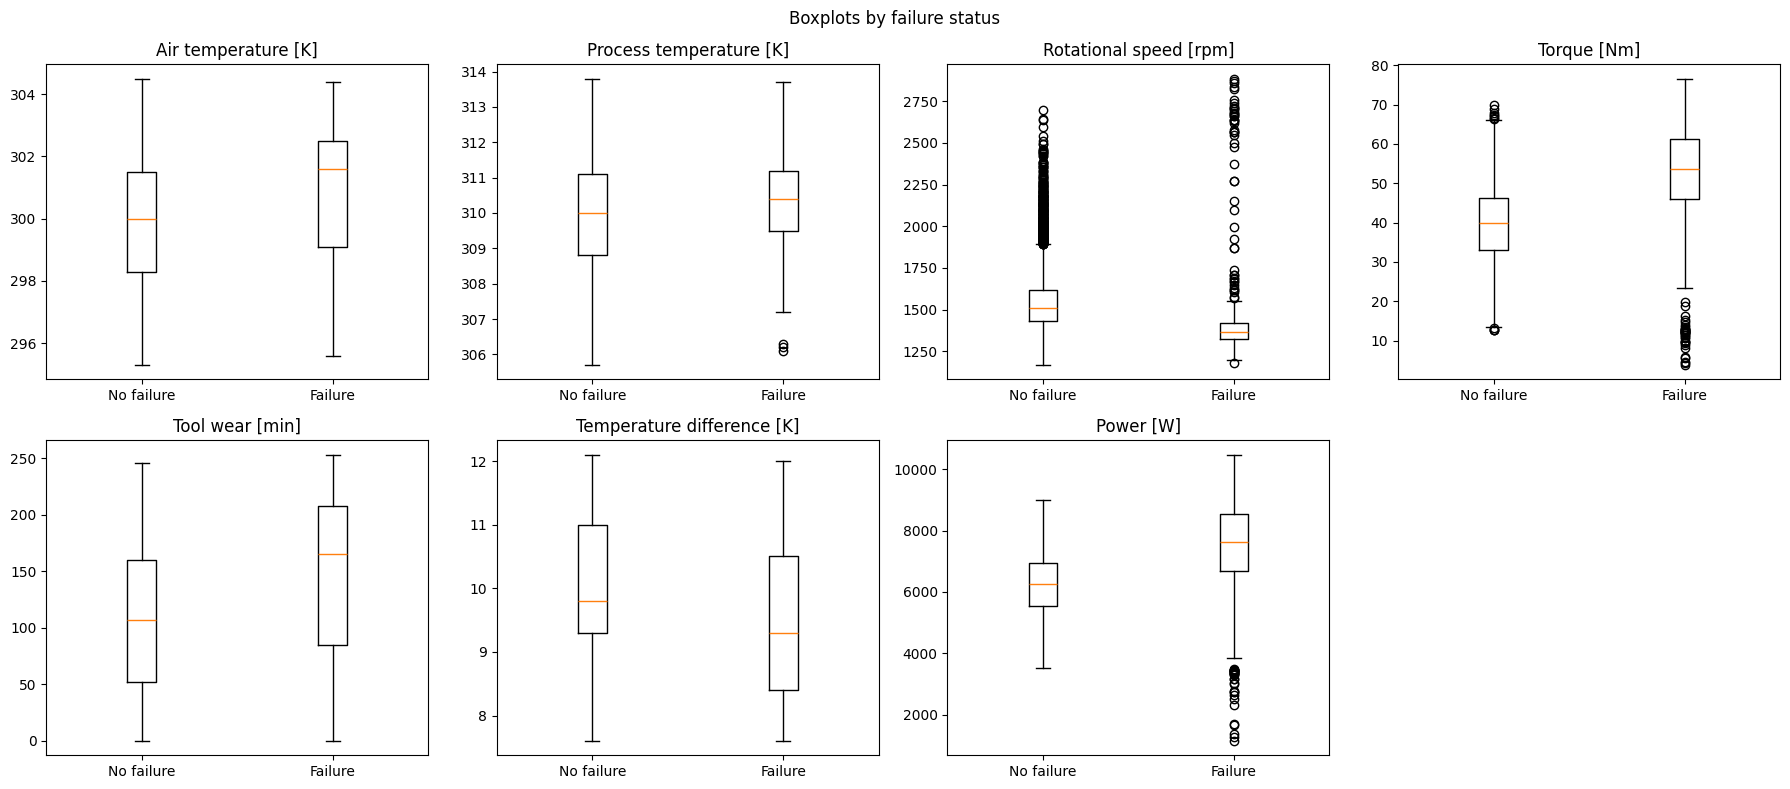

In [10]:
for plot_type in ["hist", "box"]:
    fig, axes = plt.subplots(2, 4, figsize=(18, 8))
    for ax, col in zip(axes.flat, numeric_features):
        no_fail = analysis_df.loc[analysis_df["Machine failure"] == 0, col]
        fail = analysis_df.loc[analysis_df["Machine failure"] == 1, col]
        if plot_type == "hist":
            ax.hist(no_fail, bins=30, alpha=0.6, density=True, label="No failure")
            ax.hist(fail, bins=30, alpha=0.6, density=True, label="Failure")
            ax.legend()
        else:
            ax.boxplot([no_fail, fail], tick_labels=["No failure", "Failure"])
        ax.set_title(col)
    axes.flat[-1].axis("off")
    fig.suptitle("Distributions by failure status" if plot_type == "hist" else "Boxplots by failure status")
    plt.tight_layout()
    plt.show()

## 4. Leakage-Safe Data Preparation and Train/Test Split

**Purpose:** to prepare the data for modelling without letting the model "see the answer". Only eight allowed predictors are used; identifiers and the five failure-mode columns are excluded because they reveal the outcome (target leakage). The data is then split once into training (80%) and test (20%) sets, keeping the same 3.4% failure rate in both. The preprocessing is defined here but fitted later inside each model pipeline, using training data only.

### 4.1 Define features, target and excluded variables

The eight predictors are product type, the five raw sensor readings and the two engineered features. UDI and Product ID are identifiers, and TWF, HDF, PWF, OSF and RNF are failure-mode labels, so all seven are excluded. A check stops the notebook if any excluded column or the target ends up among the features.

In [11]:

numeric_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
                    "Torque [Nm]", "Tool wear [min]", "Temperature difference [K]", "Power [W]"]
categorical_features = ["Type"]
feature_columns = categorical_features + numeric_features
target_column = "Machine failure"
excluded_variables = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

# Leakage check: stop here if an identifier, failure mode or the target is in the features
assert not set(feature_columns) & set(excluded_variables + [target_column]), "Leakage: excluded column in features"

X = analysis_df[feature_columns].copy()
y = analysis_df[target_column].copy()

print("Features used  :", feature_columns)
print("Excluded       :", excluded_variables)
print("Target         :", target_column)
print("X shape:", X.shape, "| y shape:", y.shape)

Features used  : ['Type', 'Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Power [W]']
Excluded       : ['UDI', 'Product ID', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']
Target         : Machine failure
X shape: (10000, 8) | y shape: (10000,)


In [12]:
# Data-quality checks: stop if anything unexpected is in the data
assert set(analysis_df["Type"].unique()) == {"L", "M", "H"}, "Unexpected product type"
assert set(analysis_df[target_column].unique()) == {0, 1}, "Target must be 0 or 1"
assert (analysis_df[numeric_features] >= 0).all().all(), "Negative values found"
assert analysis_df[feature_columns].notnull().all().all(), "Missing values found"

print("Data-quality checks passed: product types L/M/H, target 0/1, no negative readings, no missing values")
display(analysis_df[numeric_features].agg(["min", "max"]).T.round(2))

Data-quality checks passed: product types L/M/H, target 0/1, no negative readings, no missing values


,min,max
Air temperature [K],295.30,304.50
Process temperature [K],305.70,313.80
Rotational speed [rpm],1168.00,2886.00
Torque [Nm],3.80,76.60
Tool wear [min],0.00,253.00
Temperature difference [K],7.60,12.10
Power [W],1148.44,10469.92


### 4.2 Stratified train/test split

80% of the rows (8,000) are used for training and 20% (2,000) for testing. `stratify=y` keeps the failure rate the same in both sets, and `random_state=42` makes the split identical every time the notebook runs. A final check confirms there are no missing values after the split.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

def class_counts(target):
    return pd.DataFrame({"Count": target.value_counts().sort_index(),
                         "Percentage (%)": (target.value_counts(normalize=True).sort_index() * 100).round(2)},
                        ).rename(index={0: "No failure (0)", 1: "Failure (1)"})

split_summary = pd.concat({"Full data": class_counts(y), "Training (80%)": class_counts(y_train),
                           "Test (20%)": class_counts(y_test)}, axis=1)
display(split_summary)

print("\nMissing values X_train:", X_train.isnull().sum().sum(), "| X_test:", X_test.isnull().sum().sum(),
      "| y_train:", y_train.isnull().sum(), "| y_test:", y_test.isnull().sum())

Full data                Training (80%)                 \
                    Count Percentage (%)          Count Percentage (%)   
Machine failure                                                          
No failure (0)       9661          96.61           7729          96.61   
Failure (1)           339           3.39            271           3.39   

                Test (20%)                 
                     Count Percentage (%)  
Machine failure                            
No failure (0)        1932           96.6  
Failure (1)             68            3.4


Missing values X_train: 0 | X_test: 0 | y_train: 0 | y_test: 0


### 4.3 Preprocessing pipeline

Numeric features are standardised (mean 0, standard deviation 1), which Logistic Regression needs and tree models are unaffected by. Product type is one-hot encoded (L, M, H become dummy columns, dropping one to avoid redundancy). The preprocessor is only *defined* here; it is fitted inside each model pipeline on training data, so no information from the test set leaks into it.

In [14]:
preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("scaler", StandardScaler())]), numeric_features),
    ("categorical", Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore", drop="first"))]), categorical_features),
])
print("Preprocessor ready: StandardScaler for", len(numeric_features), "numeric features, OneHotEncoder for Type")

Preprocessor ready: StandardScaler for 7 numeric features, OneHotEncoder for Type


### 4.4 Keep test identifiers for the maintenance ranking

The identifiers were excluded from the model, but they are needed later to name each machine in the maintenance priority list and dashboard. They are saved for the 2,000 test rows only, in the same order as `X_test`.

In [15]:
test_identifiers = analysis_df.loc[X_test.index, ["UDI", "Product ID", "Type", "Machine failure"]].copy()
print("Test identifiers saved:", len(test_identifiers))
display(test_identifiers.head())

Test identifiers saved: 2000


,UDI,Product ID,Type,Machine failure
2997,2998,L50177,L,0
4871,4872,L52051,L,0
3858,3859,L51038,L,0
951,952,H30365,H,0
6463,6464,H35877,H,0


## 5. Baseline Models

**Purpose:** to set a reference point that later models must beat. Two simple baselines are trained on the training set and scored on the test set at the standard 0.5 threshold:

- **Dummy Classifier:** always predicts "no failure". It shows how misleading accuracy is when failures are rare.
- **Logistic Regression:** a simple, transparent linear model with no special handling of the imbalance.

### 5.1 Evaluation function

One reusable function scores any fitted model on the test set. It reports how many failures were found, missed or falsely flagged, together with accuracy, precision, recall, F1, ROC-AUC and PR-AUC. PR-AUC is the most informative measure here because failures are rare.

In [16]:

def evaluate_model(model_name, model, X_test, y_test):
    """Score a fitted model on the test set and print its confusion matrix."""
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    print(f"{model_name}: {tp} failures found, {fn} missed, {fp} false alarms, {tn} correct non-failures")
    results = {"Model": model_name,
               "Accuracy": accuracy_score(y_test, y_pred),
               "Precision": precision_score(y_test, y_pred, zero_division=0),
               "Recall": recall_score(y_test, y_pred, zero_division=0),
               "F1-score": f1_score(y_test, y_pred, zero_division=0),
               "ROC-AUC": roc_auc_score(y_test, y_prob),
               "PR-AUC": average_precision_score(y_test, y_prob)}
    return results, y_pred, y_prob

### 5.2 Train and evaluate the baselines

Both models are wrapped in a pipeline with the preprocessor, so scaling and encoding are learned from the training data only.

**What to look for:** the Dummy Classifier reaches 96.6% accuracy while finding zero failures, which is why accuracy is not used to choose models. Logistic Regression ranks failures well (ROC-AUC 0.925), but at the 0.5 threshold it finds only 12 of the 68 test failures. It is a useful transparent benchmark, but it cannot capture the non-linear risk patterns seen in the exploratory analysis.

In [17]:
# Dummy: always predicts the most common class ("no failure")
dummy_pipeline = Pipeline([("preprocessor", preprocessor),
                           ("classifier", DummyClassifier(strategy="most_frequent"))])
dummy_pipeline.fit(X_train, y_train)

# Logistic Regression: simple, transparent linear model (no class weighting)
logistic_pipeline = Pipeline([("preprocessor", preprocessor),
                              ("classifier", LogisticRegression(max_iter=2000, random_state=42))])
logistic_pipeline.fit(X_train, y_train)

dummy_results, dummy_pred, dummy_prob = evaluate_model("Dummy Classifier", dummy_pipeline, X_test, y_test)
logistic_results, logistic_pred, logistic_prob = evaluate_model("Logistic Regression", logistic_pipeline, X_test, y_test)

baseline_results = pd.DataFrame([dummy_results, logistic_results])
print("\nBaseline comparison (test set, threshold 0.5)")
display(baseline_results.round(4))

Dummy Classifier: 0 failures found, 68 missed, 0 false alarms, 1932 correct non-failures
Logistic Regression: 12 failures found, 56 missed, 9 false alarms, 1923 correct non-failures

Baseline comparison (test set, threshold 0.5)


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC
0,Dummy Classifier,0.9660,0.0000,0.0000,0.0000,0.5000,0.0340
1,Logistic Regression,0.9675,0.5714,0.1765,0.2697,0.9252,0.4606


### 5.3 ROC and precision-recall curves

The ROC curve shows how well each model separates failures from non-failures across all thresholds. The precision-recall curve focuses on the rare failure class. The Dummy Classifier sits on the diagonal (ROC) and at the 3.4% failure rate (precision-recall), meaning it has no ability to detect failures.

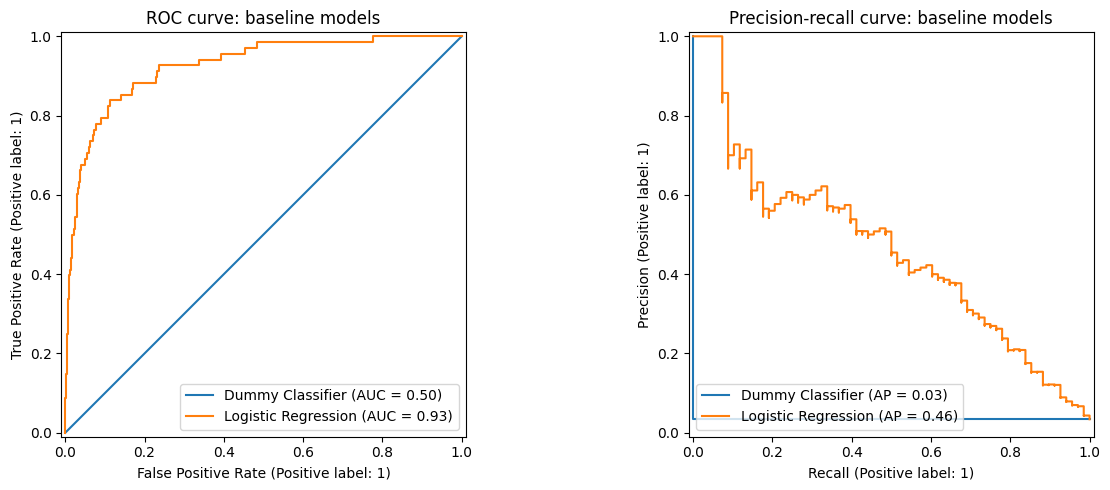

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in [("Dummy Classifier", dummy_prob), ("Logistic Regression", logistic_prob)]:
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].set_title("ROC curve: baseline models")
axes[1].set_title("Precision-recall curve: baseline models")
plt.tight_layout()
plt.show()

## 6. Imbalance-Aware Algorithm Screening

**Purpose:** to test whether non-linear models predict the rare failure class better than the baselines, and whether class weighting shifts the balance between catching failures (recall) and avoiding false alarms (precision).

Eight models are compared with the two baselines: balanced Logistic Regression, Decision Tree and Random Forest (each with and without class weighting), Gradient Boosting, and XGBoost (with and without a positive-class weight). Failures are about 28.5 times less common than non-failures in the training data, and this ratio is used as XGBoost's positive-class weight.

This is a preliminary screening on the held-out test set. It is used only to describe the models and to pick the strongest model families. The formal comparison is done with cross-validation on the training data in the next section.

### 6.1 Define the models

Each model is wrapped in a pipeline with the same preprocessor, so all models see identical inputs. "Balanced" versions give more weight to the rare failure class during training.

In [19]:

# Failures are rare: this ratio is used as the positive-class weight for Balanced XGBoost
negative_count = (y_train == 0).sum()
positive_count = (y_train == 1).sum()
scale_pos_weight = negative_count / positive_count
print(f"Training: {negative_count} non-failures, {positive_count} failures -> scale_pos_weight = {scale_pos_weight:.4f}")

xgb_settings = dict(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                    objective="binary:logistic", eval_metric="logloss", random_state=42, n_jobs=-1)

classifiers = {
    "Balanced Logistic Regression": LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42),
    "Decision Tree":                DecisionTreeClassifier(random_state=42),
    "Balanced Decision Tree":       DecisionTreeClassifier(class_weight="balanced", random_state=42),
    "Random Forest":                RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Balanced Random Forest":       RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient Boosting":            GradientBoostingClassifier(random_state=42),
    "XGBoost":                      XGBClassifier(**xgb_settings),
    "Balanced XGBoost":             XGBClassifier(**xgb_settings, scale_pos_weight=scale_pos_weight),
}
models = {name: Pipeline([("preprocessor", preprocessor), ("classifier", clf)]) for name, clf in classifiers.items()}
print("Models prepared:", ", ".join(models))

Training: 7729 non-failures, 271 failures -> scale_pos_weight = 28.5203
Models prepared: Balanced Logistic Regression, Decision Tree, Balanced Decision Tree, Random Forest, Balanced Random Forest, Gradient Boosting, XGBoost, Balanced XGBoost


### 6.2 Train, evaluate and compare

Each model is trained on the training set and scored on the test set at the 0.5 threshold, using accuracy, precision, recall, specificity, F1, ROC-AUC and PR-AUC, plus the confusion-matrix counts. The two baselines are added so that all ten models appear in one table.

**What to look for:**
- Tree ensembles (Random Forest, Gradient Boosting, XGBoost) clearly outperform the linear models, with PR-AUC around 0.89 against 0.47.
- Class weighting raises recall but costs precision. Balanced Logistic Regression finds 59 of 68 failures but raises 273 false alarms.
- No single model wins on every measure, so the leading tree models move on to cross-validation.

In [20]:
def screening_row(name, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    return {"Model": name,
            "Accuracy": accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "Specificity": tn / (tn + fp),
            "F1-score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

# Start with the two baselines from Section 5, then add each screened model
rows = [screening_row("Dummy Classifier", dummy_pred, dummy_prob),
        screening_row("Logistic Regression", logistic_pred, logistic_prob)]
for name, model in models.items():
    model.fit(X_train, y_train)
    rows.append(screening_row(name, model.predict(X_test), model.predict_proba(X_test)[:, 1]))

all_algorithm_results = pd.DataFrame(rows)
print("Model comparison (test set, threshold 0.5)")
display(all_algorithm_results.round(4))

for metric in ["PR-AUC", "Recall", "F1-score", "ROC-AUC"]:
    best = all_algorithm_results.loc[all_algorithm_results[metric].idxmax()]
    print(f"Best {metric:<8}: {best['Model']} ({best[metric]:.4f})")

Model comparison (test set, threshold 0.5)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Dummy Classifier,0.9660,0.0000,0.0000,1.0000,0.0000,0.5000,0.0340,0,0,68,1932
1,Logistic Regression,0.9675,0.5714,0.1765,0.9953,0.2697,0.9252,0.4606,12,9,56,1923
2,Balanced Logistic Regression,0.8590,0.1777,0.8676,0.8587,0.2950,0.9339,0.4660,59,273,9,1659
3,Decision Tree,0.9850,0.8065,0.7353,0.9938,0.7692,0.8645,0.6020,50,12,18,1920
4,Balanced Decision Tree,0.9850,0.8276,0.7059,0.9948,0.7619,0.8504,0.5942,48,10,20,1922
5,Random Forest,0.9915,0.9474,0.7941,0.9984,0.8640,0.9792,0.8853,54,3,14,1929
6,Balanced Random Forest,0.9895,0.9434,0.7353,0.9984,0.8264,0.9780,0.8630,50,3,18,1929
7,Gradient Boosting,0.9910,0.9464,0.7794,0.9984,0.8548,0.9759,0.8998,53,3,15,1929
8,XGBoost,0.9900,0.9286,0.7647,0.9979,0.8387,0.9823,0.8878,52,4,16,1928
9,Balanced XGBoost,0.9815,0.6742,0.8824,0.9850,0.7643,0.9783,0.8868,60,29,8,1903


Best PR-AUC  : Gradient Boosting (0.8998)
Best Recall  : Balanced XGBoost (0.8824)
Best F1-score: Random Forest (0.8640)
Best ROC-AUC : XGBoost (0.9823)


In [21]:
import os
os.makedirs("outputs", exist_ok=True)
all_algorithm_results.to_csv("outputs/model_screening_results.csv", index=False)

## 7. Stratified Cross-Validation and Model Stability

**Purpose:** to check whether the leading models from the screening perform well *consistently*, not just on one lucky train/test split. Random Forest, Gradient Boosting, XGBoost and Balanced XGBoost are each evaluated with 5-fold stratified cross-validation on the training data only.

Stratification keeps the small failure rate the same in every fold, and shuffling with a fixed random state makes the folds reproducible. For each model the mean score shows typical performance, and the standard deviation (SD) across folds shows how stable it is. PR-AUC is the main measure because it focuses on the rare failures. These results decide which models go forward to hyperparameter tuning.

### 7.1 Cross-validation design and models

The training data (8,000 rows) is split into 5 folds. Each model is trained on 4 folds and tested on the 5th, five times over. The four models use exactly the same settings as in the screening.

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5 folds, stratified so every fold keeps the ~3.4% failure rate; shuffled with a fixed seed
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"5-fold stratified CV on {len(X_train)} training rows ({int(y_train.sum())} failures, {y_train.mean():.2%})")

# The four leading models from the screening, with the same settings as before
cv_models = {
    "Random Forest":     RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "XGBoost":           XGBClassifier(**xgb_settings),
    "Balanced XGBoost":  XGBClassifier(**xgb_settings, scale_pos_weight=scale_pos_weight),
}
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall",
           "F1": "f1", "ROC-AUC": "roc_auc", "PR-AUC": "average_precision"}
print("Models:", ", ".join(cv_models))

5-fold stratified CV on 8000 training rows (271 failures, 3.39%)
Models: Random Forest, Gradient Boosting, XGBoost, Balanced XGBoost


### 7.2 Run cross-validation: mean and variability

Each model is scored on six measures in every fold. The table shows the mean ± standard deviation across the 5 folds. A small SD means the model behaves consistently on different subsets of the data.

**What to look for:**
- Gradient Boosting has the highest mean PR-AUC (0.885) and the smallest variation (± 0.013).
- Random Forest is close behind (0.880) with the highest precision (0.977) and F1 (0.836), meaning very few false alarms.
- Balanced XGBoost finds the most failures (recall 0.830) but at much lower precision (0.700).

In [23]:
summary_rows, fold_rows = [], []
for name, clf in cv_models.items():
    pipeline = Pipeline([("preprocessor", preprocessor), ("classifier", clf)])
    scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)

    row = {"Model": name}
    for metric in scoring:
        row[f"{metric} Mean"] = scores[f"test_{metric}"].mean()
        row[f"{metric} SD"] = scores[f"test_{metric}"].std()
    summary_rows.append(row)

    for fold in range(5):
        fold_rows.append({"Model": name, "Fold": fold + 1,
                          **{metric: scores[f"test_{metric}"][fold] for metric in ["PR-AUC", "ROC-AUC", "Recall", "Precision", "F1"]}})

cv_summary = pd.DataFrame(summary_rows)
cv_folds = pd.DataFrame(fold_rows)

# Mean ± standard deviation across the 5 folds
cv_table = cv_summary[["Model"]].copy()
for metric in scoring:
    cv_table[metric] = [f"{m:.3f} ± {s:.3f}" for m, s in zip(cv_summary[f"{metric} Mean"], cv_summary[f"{metric} SD"])]
print("Cross-validation results (mean ± SD over 5 folds)")
display(cv_table)

Cross-validation results (mean ± SD over 5 folds)


,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Random Forest,0.990 ± 0.002,0.977 ± 0.014,0.735 ± 0.068,0.836 ± 0.040,0.975 ± 0.014,0.880 ± 0.032
1,Gradient Boosting,0.989 ± 0.001,0.922 ± 0.032,0.757 ± 0.058,0.829 ± 0.025,0.981 ± 0.013,0.885 ± 0.013
2,XGBoost,0.987 ± 0.002,0.889 ± 0.045,0.720 ± 0.060,0.793 ± 0.035,0.978 ± 0.012,0.848 ± 0.035
3,Balanced XGBoost,0.982 ± 0.003,0.700 ± 0.043,0.830 ± 0.030,0.759 ± 0.036,0.978 ± 0.010,0.831 ± 0.044


### 7.3 Fold-by-fold results and best models

The individual fold scores show where the variation comes from. For example, Random Forest's recall ranges from 0.65 to 0.83 between folds, so a single split could have made it look noticeably better or worse. The best model on each measure is listed at the end. No single model wins everything, so Random Forest, Gradient Boosting and XGBoost go forward to hyperparameter tuning.

In [24]:
print("Fold-by-fold results")
display(cv_folds.round(4))

for metric in ["PR-AUC", "F1", "Recall", "ROC-AUC"]:
    best = cv_summary.loc[cv_summary[f"{metric} Mean"].idxmax()]
    print(f"Best mean {metric:<8}: {best['Model']} ({best[f'{metric} Mean']:.4f})")

Fold-by-fold results


,Model,Fold,PR-AUC,ROC-AUC,Recall,Precision,F1
0,Random Forest,1,0.9228,0.9922,0.8333,0.9574,0.8911
1,Random Forest,2,0.8250,0.9760,0.6481,1.0000,0.7865
2,Random Forest,3,0.8762,0.9585,0.7778,0.9767,0.8660
3,Random Forest,4,0.8978,0.9896,0.7407,0.9756,0.8421
4,Random Forest,5,0.8780,0.9596,0.6727,0.9737,0.7957
5,Gradient Boosting,1,0.9083,0.9940,0.8333,0.8654,0.8491
6,Gradient Boosting,2,0.8712,0.9897,0.7037,0.9268,0.8000
7,Gradient Boosting,3,0.8786,0.9607,0.8148,0.9167,0.8627
8,Gradient Boosting,4,0.8881,0.9897,0.7407,0.9524,0.8333
9,Gradient Boosting,5,0.8773,0.9702,0.6909,0.9500,0.8000


Best mean PR-AUC  : Gradient Boosting (0.8847)
Best mean F1      : Random Forest (0.8363)
Best mean Recall  : Balanced XGBoost (0.8302)
Best mean ROC-AUC : Gradient Boosting (0.9808)


In [25]:
cv_summary.to_csv("outputs/cross_validation_summary.csv", index=False)
cv_folds.to_csv("outputs/cross_validation_folds.csv", index=False)

## 8. Hyperparameter Optimisation

**Purpose:** to fine-tune the three strongest tree-based models (Random Forest, Gradient Boosting and XGBoost) so each is compared at its best settings. A randomised search tries 30 parameter combinations per model, scoring each with 5-fold stratified cross-validation on the training data only. The test set plays no part in choosing parameters.

PR-AUC (average precision) is the optimisation target because failures are rare. Each search covers model complexity (number of trees, depth, leaf size), learning behaviour (learning rate), sampling (subsample, column sampling), regularisation (XGBoost) and class weighting (Random Forest). The best setting for each model is refitted on the full training data and kept for the final evaluation.

### 8.1 Define the search spaces

For each model, the list of values to try for every parameter. The search picks 30 random combinations from these lists, using a fixed random state so the same combinations are tried every run.

In [26]:


# Same 5-fold stratified design as the cross-validation step; training data only
tuning_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Search space for each model: (base model, parameter options to try)
search_spaces = {
    "Random Forest": (
        RandomForestClassifier(random_state=42, n_jobs=-1),
        {"n_estimators": [200, 300, 500, 700],
         "max_depth": [None, 6, 10, 15, 20],
         "min_samples_split": [2, 5, 10],
         "min_samples_leaf": [1, 2, 4],
         "max_features": ["sqrt", "log2", None],
         "class_weight": [None, "balanced", "balanced_subsample"]}),
    "Gradient Boosting": (
        GradientBoostingClassifier(random_state=42),
        {"n_estimators": [50, 100, 150, 200, 300],
         "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
         "max_depth": [1, 2, 3, 4, 5],
         "min_samples_split": [2, 5, 10],
         "min_samples_leaf": [1, 2, 4],
         "subsample": [0.7, 0.8, 0.9, 1.0],
         "max_features": [None, "sqrt", "log2"]}),
    "XGBoost": (
        XGBClassifier(objective="binary:logistic", eval_metric="logloss", random_state=42, n_jobs=-1),
        {"n_estimators": [100, 200, 300, 500],
         "learning_rate": [0.01, 0.03, 0.05, 0.1],
         "max_depth": [2, 3, 4, 5, 6],
         "min_child_weight": [1, 3, 5, 7],
         "subsample": [0.7, 0.8, 0.9, 1.0],
         "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
         "gamma": [0, 0.1, 0.3, 0.5],
         "reg_lambda": [1, 2, 5, 10],
         "reg_alpha": [0, 0.01, 0.1, 0.5]}),
}
print("Method: RandomizedSearchCV | 30 settings per model | 5-fold stratified CV | metric: PR-AUC")
print("Training rows used:", len(X_train), "| Test set used: NO")

Method: RandomizedSearchCV | 30 settings per model | 5-fold stratified CV | metric: PR-AUC
Training rows used: 8000 | Test set used: NO


### 8.2 Run the searches

Each model is tuned in turn (30 settings × 5 folds = 150 fits per model). This is the slowest part of the notebook, roughly 10–15 minutes in total, mostly for Random Forest. The best cross-validated PR-AUC and the winning parameters are printed for each model, and the refitted best pipelines are saved for the final evaluation.

In [27]:
best_models = {}
for name, (model, grid) in search_spaces.items():
    print(f"\n{name}")
    search = RandomizedSearchCV(
        Pipeline([("preprocessor", preprocessor), ("classifier", model)]),
        param_distributions={f"classifier__{key}": values for key, values in grid.items()},
        n_iter=30, scoring="average_precision", cv=tuning_cv, random_state=42, n_jobs=-1, verbose=1)

    start = time.time()
    search.fit(X_train, y_train)

    best_models[name] = search
    print(f"Best CV PR-AUC: {search.best_score_:.4f}  (runtime {time.time() - start:.0f} s)")
    print("Best parameters:", {key.replace("classifier__", ""): value for key, value in search.best_params_.items()})

# Keep the refitted best pipelines for the final evaluation
best_rf_model = best_models["Random Forest"].best_estimator_
best_gb_model = best_models["Gradient Boosting"].best_estimator_
best_xgb_model = best_models["XGBoost"].best_estimator_


Random Forest
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV PR-AUC: 0.8859  (runtime 793 s)
Best parameters: {'n_estimators': 700, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': None, 'max_depth': 10, 'class_weight': None}

Gradient Boosting
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV PR-AUC: 0.8904  (runtime 152 s)
Best parameters: {'subsample': 0.9, 'n_estimators': 150, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 5, 'learning_rate': 0.03}

XGBoost
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best CV PR-AUC: 0.8610  (runtime 33 s)
Best parameters: {'subsample': 0.8, 'reg_lambda': 5, 'reg_alpha': 0.5, 'n_estimators': 200, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.05, 'gamma': 0.3, 'colsample_bytree': 0.8}


### 8.3 Tuning comparison

Compares each model's cross-validated PR-AUC before tuning (default settings from the cross-validation step) and after tuning.

**What to look for:** tuning gives small but consistent gains. XGBoost improves the most (+1.6%), but Gradient Boosting (0.8904) and Random Forest (0.8859) remain clearly ahead of XGBoost (0.8610). The gap between the top two is small (0.0045), so the final choice also considers precision, false alarms and probability quality.

In [28]:
tuning_summary = pd.DataFrame({
    "Model": list(best_models),
    "Untuned CV PR-AUC": [cv_summary.set_index("Model").loc[name, "PR-AUC Mean"] for name in best_models],
    "Tuned CV PR-AUC": [search.best_score_ for search in best_models.values()],
})
tuning_summary["Improvement"] = tuning_summary["Tuned CV PR-AUC"] - tuning_summary["Untuned CV PR-AUC"]
tuning_summary["Improvement (%)"] = tuning_summary["Improvement"] / tuning_summary["Untuned CV PR-AUC"] * 100
display(tuning_summary.round(4))

best_tuned = tuning_summary.loc[tuning_summary["Tuned CV PR-AUC"].idxmax()]
print(f"\nHighest tuned CV PR-AUC: {best_tuned['Model']} ({best_tuned['Tuned CV PR-AUC']:.4f})")
tuning_summary.to_csv("outputs/tuning_summary.csv", index=False)

,Model,Untuned CV PR-AUC,Tuned CV PR-AUC,Improvement,Improvement (%)
0,Random Forest,0.8800,0.8859,0.0059,0.6697
1,Gradient Boosting,0.8847,0.8904,0.0057,0.6432
2,XGBoost,0.8476,0.8610,0.0134,1.5799



Highest tuned CV PR-AUC: Gradient Boosting (0.8904)


## 9. Final Evaluation of Tuned Models

**Purpose:** to compare the three tuned models (Random Forest, Gradient Boosting and XGBoost) on the 2,000-row held-out test set, using accuracy, precision, recall, specificity, F1, ROC-AUC, PR-AUC, confusion-matrix counts and ROC / precision-recall curves.

At the default 0.5 threshold, the tuned Random Forest gives the best overall balance: PR-AUC 0.8985, precision 0.9483, recall 0.8088 and F1 0.8730, with only 3 false alarms. Tuned Gradient Boosting has a similar PR-AUC and better recall and F1 than XGBoost, but slightly lower ROC-AUC. A comparison on the training data (out-of-fold) explains why Random Forest is taken forward. The predicted probabilities are saved for the threshold, calibration, uncertainty and explainability steps that follow.

### 9.1 Evaluate the tuned models on the test set

Each tuned model predicts the 2,000 test rows. The same metrics as in the screening step are reported, together with how many of the 68 test failures were found, missed or falsely flagged.

In [29]:
tuned_models = {"Tuned Random Forest": best_rf_model,
                "Tuned Gradient Boosting": best_gb_model,
                "Tuned XGBoost": best_xgb_model}

rows, test_probabilities = [], {}
for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    test_probabilities[name] = y_prob
    row = screening_row(name, y_pred, y_prob)   # same metrics as the screening step
    rows.append(row)
    print(f"{name}: {row['TP']} of 68 failures found, {row['FN']} missed, {row['FP']} false alarms")

final_tuned_results = pd.DataFrame(rows)
print("\nTuned models on the test set (threshold 0.5)")
display(final_tuned_results.round(4))
final_tuned_results.to_csv("outputs/tuned_models_test_results.csv", index=False)

rf_final_prob = test_probabilities["Tuned Random Forest"]
gb_final_prob = test_probabilities["Tuned Gradient Boosting"]
xgb_final_prob = test_probabilities["Tuned XGBoost"]

Tuned Random Forest: 55 of 68 failures found, 13 missed, 3 false alarms
Tuned Gradient Boosting: 52 of 68 failures found, 16 missed, 3 false alarms
Tuned XGBoost: 50 of 68 failures found, 18 missed, 5 false alarms

Tuned models on the test set (threshold 0.5)


,Model,Accuracy,Precision,Recall,Specificity,F1-score,ROC-AUC,PR-AUC,TP,FP,FN,TN
0,Tuned Random Forest,0.9920,0.9483,0.8088,0.9984,0.8730,0.9838,0.8985,55,3,13,1929
1,Tuned Gradient Boosting,0.9905,0.9455,0.7647,0.9984,0.8455,0.9795,0.8972,52,3,16,1929
2,Tuned XGBoost,0.9885,0.9091,0.7353,0.9974,0.8130,0.9849,0.8933,50,5,18,1927


### 9.2 Untuned vs tuned performance

Compares each model before tuning (screening results) and after tuning, on the same test set. Tuning clearly helps Random Forest (PR-AUC 0.8853 → 0.8985, recall 0.7941 → 0.8088). For Gradient Boosting and XGBoost the test results move slightly in both directions, which shows that small differences on one test set should not be over-interpreted.

In [30]:
metrics = ["Precision", "Recall", "F1-score", "ROC-AUC", "PR-AUC"]
untuned = all_algorithm_results.set_index("Model").loc[["Random Forest", "Gradient Boosting", "XGBoost"], metrics]
tuned = final_tuned_results.set_index("Model")[metrics]
tuned.index = untuned.index
untuned_vs_tuned = pd.concat({"Untuned": untuned, "Tuned": tuned}).swaplevel().sort_index(level=0, sort_remaining=False)
display(untuned_vs_tuned.loc[["Random Forest", "Gradient Boosting", "XGBoost"]].round(4))

Precision  Recall  F1-score  ROC-AUC  PR-AUC
Model                                                                  
Random Forest     Untuned     0.9474  0.7941    0.8640   0.9792  0.8853
                  Tuned       0.9483  0.8088    0.8730   0.9838  0.8985
Gradient Boosting Untuned     0.9464  0.7794    0.8548   0.9759  0.8998
                  Tuned       0.9455  0.7647    0.8455   0.9795  0.8972
XGBoost           Untuned     0.9286  0.7647    0.8387   0.9823  0.8878
                  Tuned       0.9091  0.7353    0.8130   0.9849  0.8933

### 9.3 ROC and precision-recall curves

The ROC curves show that all three tuned models separate failures from non-failures very well (ROC-AUC 0.98). The precision-recall curves are more informative for rare failures: all three stay high until most failures are found, then precision drops. The figure is also saved to the outputs folder.

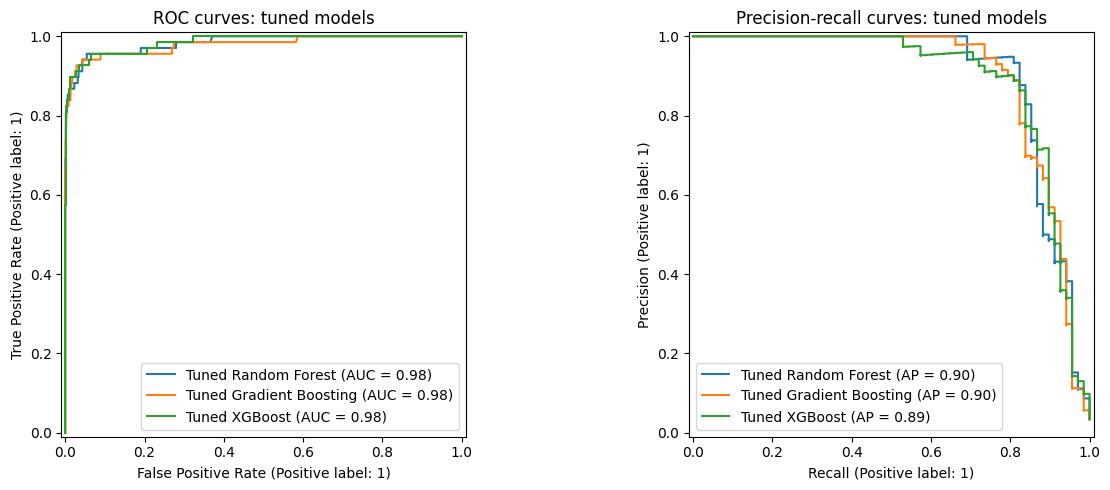

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, prob in test_probabilities.items():
    RocCurveDisplay.from_predictions(y_test, prob, name=name, ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test, prob, name=name, ax=axes[1])
axes[0].set_title("ROC curves: tuned models")
axes[1].set_title("Precision-recall curves: tuned models")
plt.tight_layout()
plt.savefig("outputs/tuned_models_roc_pr_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### 9.4 Why Random Forest is taken forward (training-data evidence)

The model choice should not rest on the test set alone. Here each tuned model is compared using out-of-fold predictions on the training data: every training row is predicted by a model that never saw it during training. Three things are compared:
- **PR-AUC:** overall ability to rank failures above non-failures
- **Brier score:** how accurate the predicted probabilities are (lower is better)
- **Best F1** and the **precision** at that threshold: how well the model performs at its best operating point

**Result:** Gradient Boosting has a marginally higher PR-AUC (difference about 0.004), but Random Forest gives the most reliable probabilities (lowest Brier score), a higher best F1, and much higher precision at its best threshold (about 0.95 vs 0.87, meaning far fewer false alarms). Since the next steps use these probabilities to rank machines for inspection, Random Forest is taken forward as the final model.

In [32]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import brier_score_loss

selection_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
thresholds = np.arange(0.01, 0.96, 0.01)

selection_rows = []
for name, model in tuned_models.items():
    # Out-of-fold probabilities: each training row is predicted by a model that never saw it
    oof_prob = cross_val_predict(model, X_train, y_train, cv=selection_cv, method="predict_proba", n_jobs=-1)[:, 1]
    f1_scores = [f1_score(y_train, (oof_prob >= t).astype(int)) for t in thresholds]
    best_t = thresholds[int(np.argmax(f1_scores))]
    selection_rows.append({"Model": name,
                           "OOF PR-AUC": average_precision_score(y_train, oof_prob),
                           "OOF Brier score": brier_score_loss(y_train, oof_prob),
                           "Best OOF F1": max(f1_scores),
                           "At threshold": round(best_t, 2),
                           "Precision at that threshold": precision_score(y_train, (oof_prob >= best_t).astype(int))})

model_selection = pd.DataFrame(selection_rows)
print("Training-data (out-of-fold) comparison of the tuned models")
display(model_selection.round(5))
model_selection.to_csv("outputs/model_selection_training_data.csv", index=False)

Training-data (out-of-fold) comparison of the tuned models


,Model,OOF PR-AUC,OOF Brier score,Best OOF F1,At threshold,Precision at that threshold
0,Tuned Random Forest,0.88554,0.00845,0.84959,0.42,0.94570
1,Tuned Gradient Boosting,0.88916,0.00858,0.84040,0.37,0.92857
2,Tuned XGBoost,0.85742,0.01030,0.81746,0.41,0.88412


### 9.5 Save the test-set probabilities

The predicted failure probability of each tuned model is stored next to the machine identifiers for the 2,000 test rows. Later steps use the Random Forest probabilities for threshold selection, calibration, uncertainty, SHAP and the maintenance ranking.

In [33]:
final_test_predictions = test_identifiers.copy()
final_test_predictions["RF_Failure_Probability"] = rf_final_prob
final_test_predictions["GB_Failure_Probability"] = gb_final_prob
final_test_predictions["XGB_Failure_Probability"] = xgb_final_prob

final_test_predictions.to_csv("outputs/test_set_probabilities.csv")
display(final_test_predictions.head())

,UDI,Product ID,Type,Machine failure,RF_Failure_Probability,GB_Failure_Probability,XGB_Failure_Probability
2997,2998,L50177,L,0,0.003192,0.017496,0.050954
4871,4872,L52051,L,0,0.000025,0.001769,0.000796
3858,3859,L51038,L,0,0.043473,0.048538,0.057963
951,952,H30365,H,0,0.000022,0.001987,0.001318
6463,6464,H35877,H,0,0.000002,0.010239,0.010171


## 10. Descriptive Decision-Threshold Analysis

**Purpose:** to show how the tuned Random Forest behaves at decision thresholds other than the default 0.50. Precision, recall, F1, specificity, false positive rate, false negative rate and the Youden index are calculated for every threshold from 0.05 to 0.95.

This shows the operational trade-off between finding failures and creating maintenance alerts: a lower threshold catches more failures but raises more false alarms, and a higher threshold gives a more selective alert list but misses more failures.

This analysis uses the test set and is **descriptive only**. It is not used to choose the final threshold, because picking an operating threshold from test-set labels would compromise the independence of the final evaluation. The final threshold is chosen from training data in the next section.

### 10.1 Metrics at every threshold

Each threshold turns the predicted probabilities into "failure" / "no failure" decisions, and the resulting errors are counted. The table shows a selection of thresholds.

**What to look for:** moving from 0.50 down to 0.10 finds 5 more failures (60 instead of 55), but false alarms rise from 3 to 55.

In [34]:
# Final model's test-set probabilities and the thresholds to try (0.05 to 0.95 in steps of 0.01)
final_probabilities = rf_final_prob
thresholds = np.arange(0.05, 0.96, 0.01)

rows = []
for t in thresholds:
    y_pred_t = (final_probabilities >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    rows.append({"Threshold": round(t, 2),
                 "Precision": precision_score(y_test, y_pred_t, zero_division=0),
                 "Recall": tp / (tp + fn),
                 "Specificity": tn / (tn + fp),
                 "F1-score": f1_score(y_test, y_pred_t, zero_division=0),
                 "False Positive Rate": fp / (fp + tn),
                 "False Negative Rate": fn / (fn + tp),
                 "Youden Index": tp / (tp + fn) + tn / (tn + fp) - 1,
                 "TP": tp, "FP": fp, "FN": fn, "TN": tn})
threshold_df = pd.DataFrame(rows)
threshold_df.to_csv("outputs/test_threshold_analysis.csv", index=False)

print(f"{len(threshold_df)} thresholds evaluated on {len(y_test)} test rows ({int(y_test.sum())} failures)")
print("\nSelected thresholds")
display(threshold_df[threshold_df["Threshold"].isin([0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60, 0.70])]
        [["Threshold", "Precision", "Recall", "Specificity", "F1-score", "TP", "FP", "FN"]].round(4))

91 thresholds evaluated on 2000 test rows (68 failures)

Selected thresholds


,Threshold,Precision,Recall,Specificity,F1-score,TP,FP,FN
5,0.10,0.5217,0.8824,0.9715,0.6557,60,55,8
10,0.15,0.6484,0.8676,0.9834,0.7421,59,32,9
15,0.20,0.7342,0.8529,0.9891,0.7891,58,21,10
20,0.25,0.8382,0.8382,0.9943,0.8382,57,11,11
25,0.30,0.8769,0.8382,0.9959,0.8571,57,8,11
30,0.35,0.9180,0.8235,0.9974,0.8682,56,5,12
35,0.40,0.9333,0.8235,0.9979,0.8750,56,4,12
40,0.45,0.9322,0.8088,0.9979,0.8661,55,4,13
45,0.50,0.9483,0.8088,0.9984,0.8730,55,3,13
50,0.55,0.9455,0.7647,0.9984,0.8455,52,3,16


### 10.2 Key threshold strategies

Four ways of choosing a threshold are compared:
- the **default 0.50**
- the threshold with the **best F1** (balance of precision and recall)
- the threshold that keeps **recall at 90% or more** with the highest precision
- the **maximum Youden index** (recall + specificity − 1)

**What to look for:** the best-F1 threshold (0.37) finds one more failure than 0.50 at the cost of one extra false alarm. Pushing recall above 90% (0.08) finds 62 of 68 failures but raises 67 false alarms. The Youden index favours very low thresholds because false alarms are rare compared with the 1,932 non-failures.

In [35]:
best_f1_row = threshold_df.loc[threshold_df["F1-score"].idxmax()]
high_recall_row = (threshold_df[threshold_df["Recall"] >= 0.90]
                   .sort_values(["Precision", "Threshold"], ascending=[False, False]).iloc[0])
best_youden_row = threshold_df.loc[threshold_df["Youden Index"].idxmax()]
default_row = threshold_df.loc[threshold_df["Threshold"] == 0.50].iloc[0]

threshold_comparison = pd.DataFrame([default_row, best_f1_row, high_recall_row, best_youden_row]).reset_index(drop=True)
threshold_comparison.insert(0, "Strategy", ["Default 0.50", "Best F1", "Recall >= 90%", "Maximum Youden Index"])
threshold_comparison = threshold_comparison.astype({"TP": int, "FP": int, "FN": int, "TN": int})
display(threshold_comparison[["Strategy", "Threshold", "Precision", "Recall", "Specificity", "F1-score",
                              "False Positive Rate", "False Negative Rate", "TP", "FP", "FN"]].round(4))

best_f1_threshold = float(best_f1_row["Threshold"])
best_youden_threshold = float(best_youden_row["Threshold"])
high_recall_threshold = float(high_recall_row["Threshold"])
print(f"\nTest-set thresholds (descriptive only): best F1 = {best_f1_threshold}, "
      f"recall >= 90% = {high_recall_threshold}, Youden = {best_youden_threshold}")

,Strategy,Threshold,Precision,Recall,Specificity,F1-score,False Positive Rate,False Negative Rate,TP,FP,FN
0,Default 0.50,0.50,0.9483,0.8088,0.9984,0.8730,0.0016,0.1912,55,3,13
1,Best F1,0.37,0.9333,0.8235,0.9979,0.8750,0.0021,0.1765,56,4,12
2,Recall >= 90%,0.08,0.4806,0.9118,0.9653,0.6294,0.0347,0.0882,62,67,6
3,Maximum Youden Index,0.05,0.4183,0.9412,0.9539,0.5792,0.0461,0.0588,64,89,4



Test-set thresholds (descriptive only): best F1 = 0.37, recall >= 90% = 0.08, Youden = 0.05


### 10.3 Threshold trade-off plots

Left: how precision, recall and F1 change as the threshold moves. Right: the number of false alarms and missed failures at each threshold. Together they make the maintenance trade-off visible: below about 0.25, false alarms climb steeply while only a few extra failures are found.

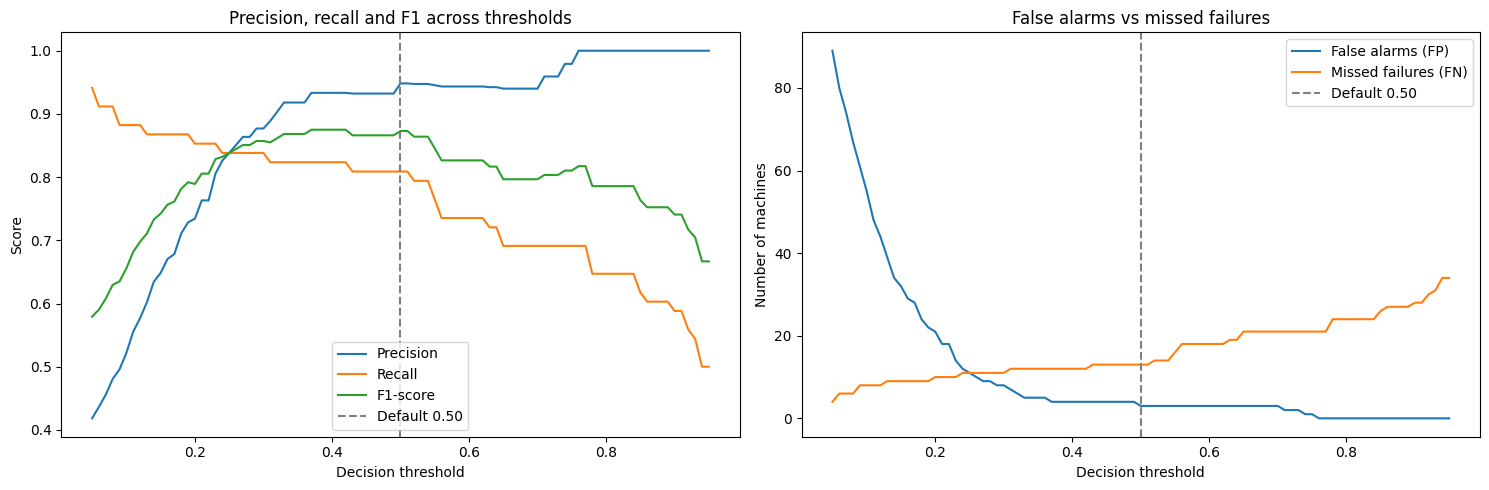

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for metric in ["Precision", "Recall", "F1-score"]:
    axes[0].plot(threshold_df["Threshold"], threshold_df[metric], label=metric)
axes[1].plot(threshold_df["Threshold"], threshold_df["FP"], label="False alarms (FP)")
axes[1].plot(threshold_df["Threshold"], threshold_df["FN"], label="Missed failures (FN)")
for ax, title, ylabel in [(axes[0], "Precision, recall and F1 across thresholds", "Score"),
                          (axes[1], "False alarms vs missed failures", "Number of machines")]:
    ax.axvline(0.50, linestyle="--", color="grey", label="Default 0.50")
    ax.set_xlabel("Decision threshold"); ax.set_ylabel(ylabel); ax.set_title(title); ax.legend()
plt.tight_layout()
plt.savefig("outputs/test_threshold_tradeoff.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Out-of-Fold Threshold Selection

**Purpose:** to choose the operating threshold *without* using the test set. Five-fold stratified cross-validation produces out-of-fold (OOF) probabilities for the 8,000 training rows: each row is predicted by a model that was trained without it. Candidate thresholds are evaluated only on these training predictions.

The threshold with the best F1 is 0.42, and the threshold that keeps recall at 90% or more with the highest precision is 0.05. These training-derived thresholds are then fixed and applied once to the test set. At 0.42, the final model reaches precision 0.9333, recall 0.8235 and F1 0.8750.

Separating threshold selection from the final evaluation gives a more defensible way to turn continuous failure probabilities into operational decisions.


### 11.1 Out-of-fold probabilities

The tuned Random Forest is cross-validated on the training data and its predicted failure probabilities are collected for every training row. The OOF ROC-AUC and PR-AUC confirm that these predictions rank failures almost as well as on the test set, so they are a reliable basis for choosing a threshold.

In [37]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# Out-of-fold probabilities for the 8,000 training rows: each row is predicted by a model trained without it
threshold_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
oof_probabilities = cross_val_predict(best_rf_model, X_train, y_train, cv=threshold_cv,
                                      method="predict_proba", n_jobs=-1)[:, 1]

print(f"Out-of-fold probabilities for {len(oof_probabilities)} training rows ({int(y_train.sum())} failures)")
print(f"OOF ROC-AUC: {roc_auc_score(y_train, oof_probabilities):.4f}")
print(f"OOF PR-AUC : {average_precision_score(y_train, oof_probabilities):.4f}")
print("Test data used to choose the threshold: NO")

Out-of-fold probabilities for 8000 training rows (271 failures)
OOF ROC-AUC: 0.9751
OOF PR-AUC : 0.8855
Test data used to choose the threshold: NO


### 11.2 Choose thresholds on the training data

Every threshold from 0.01 to 0.95 is tested on the out-of-fold predictions. Three strategies are recorded:
- **Best F1 (0.42):** the best balance of finding failures and avoiding false alarms. This becomes the operating threshold and the High-priority cut-off.
- **Recall ≥ 90% (0.05):** catches at least 90% of failures. This becomes the Medium-priority cut-off.
- **Maximum Youden index (0.01):** shown for comparison. It flags far too many machines to be practical.

In [38]:
def threshold_metrics(threshold, probabilities, actual):
    pred = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, pred).ravel()
    return {"Threshold": threshold,
            "Accuracy": accuracy_score(actual, pred),
            "Precision": precision_score(actual, pred, zero_division=0),
            "Recall": tp / (tp + fn),
            "Specificity": tn / (tn + fp),
            "F1-score": f1_score(actual, pred, zero_division=0),
            "Youden Index": tp / (tp + fn) + tn / (tn + fp) - 1,
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}

# Try every threshold from 0.01 to 0.95 on the training (out-of-fold) predictions only
oof_threshold_df = pd.DataFrame([threshold_metrics(t, oof_probabilities, y_train) for t in np.arange(0.01, 0.96, 0.01)])
oof_threshold_df.to_csv("outputs/oof_threshold_analysis.csv", index=False)

oof_best_f1_row = oof_threshold_df.loc[oof_threshold_df["F1-score"].idxmax()]
oof_high_recall_row = (oof_threshold_df[oof_threshold_df["Recall"] >= 0.90]
                       .sort_values(["Precision", "Threshold"], ascending=[False, False]).iloc[0])
oof_youden_row = oof_threshold_df.loc[oof_threshold_df["Youden Index"].idxmax()]

oof_best_f1_threshold = float(oof_best_f1_row["Threshold"])
oof_high_recall_threshold = float(oof_high_recall_row["Threshold"])
oof_youden_threshold = float(oof_youden_row["Threshold"])

oof_choice = pd.DataFrame([oof_best_f1_row, oof_high_recall_row, oof_youden_row]).reset_index(drop=True)
oof_choice.insert(0, "Strategy", ["OOF best F1", "OOF recall >= 90%", "OOF maximum Youden"])
oof_choice = oof_choice.astype({"TP": int, "FP": int, "FN": int, "TN": int})
print("Thresholds chosen on training data (out-of-fold)")
display(oof_choice.round(4))

Thresholds chosen on training data (out-of-fold)


,Strategy,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,Youden Index,TP,FP,FN,TN
0,OOF best F1,0.42,0.9908,0.9457,0.7712,0.9984,0.8496,0.7697,209,12,62,7717
1,OOF recall >= 90%,0.05,0.9545,0.4205,0.9077,0.9561,0.5748,0.8639,246,339,25,7390
2,OOF maximum Youden,0.01,0.9106,0.2707,0.9668,0.9087,0.4229,0.8754,262,706,9,7023


### 11.3 Apply the fixed thresholds to the test set

The thresholds chosen on training data are now applied, unchanged, to the 2,000 test rows. At 0.42 the model finds 56 of 68 failures with only 4 false alarms. The test-optimised threshold from the descriptive analysis (0.37) gives the same result, which shows that the training-derived choice transfers well to unseen data.

In [39]:
strategies = [("Default 0.50", 0.50), ("OOF best F1", oof_best_f1_threshold),
              ("OOF recall >= 90%", oof_high_recall_threshold), ("OOF maximum Youden", oof_youden_threshold)]
final_threshold_test_df = pd.DataFrame([{"Strategy": name, **threshold_metrics(t, rf_final_prob, y_test)}
                                        for name, t in strategies])
final_threshold_test_df = final_threshold_test_df.drop(columns="Youden Index")
print("Test-set performance at the training-derived thresholds")
display(final_threshold_test_df.round(4))
final_threshold_test_df.to_csv("outputs/test_results_at_oof_thresholds.csv", index=False)

print(f"\nThreshold if chosen on the test set (descriptive only): {best_f1_threshold:.2f}")
print(f"Threshold chosen on training data (used from here on) : {oof_best_f1_threshold:.2f}")

Test-set performance at the training-derived thresholds


,Strategy,Threshold,Accuracy,Precision,Recall,Specificity,F1-score,TP,FP,FN,TN
0,Default 0.50,0.50,0.9920,0.9483,0.8088,0.9984,0.8730,55,3,13,1929
1,OOF best F1,0.42,0.9920,0.9333,0.8235,0.9979,0.8750,56,4,12,1928
2,OOF recall >= 90%,0.05,0.9535,0.4183,0.9412,0.9539,0.5792,64,89,4,1843
3,OOF maximum Youden,0.01,0.9065,0.2610,0.9559,0.9048,0.4101,65,184,3,1748



Threshold if chosen on the test set (descriptive only): 0.37
Threshold chosen on training data (used from here on) : 0.42


### 11.4 Out-of-fold threshold curve

Precision, recall and F1 on the training (out-of-fold) predictions across all thresholds, with the chosen threshold of 0.42 marked. F1 stays fairly flat between about 0.3 and 0.5, so the result is not sensitive to the exact threshold chosen.

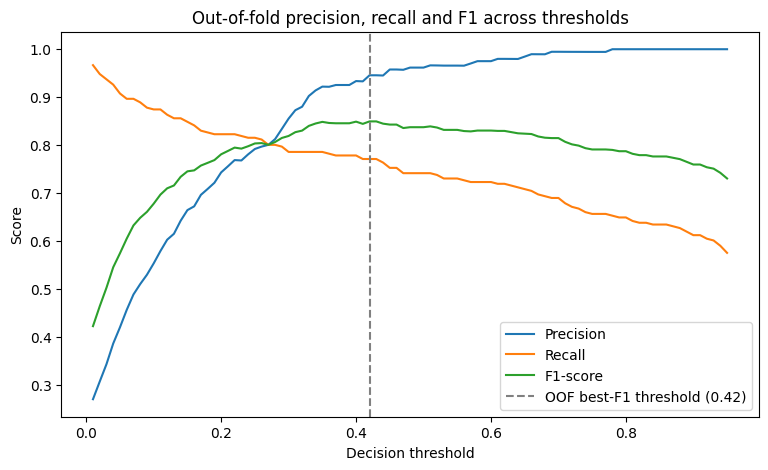

In [40]:
plt.figure(figsize=(9, 5))
for metric in ["Precision", "Recall", "F1-score"]:
    plt.plot(oof_threshold_df["Threshold"], oof_threshold_df[metric], label=metric)
plt.axvline(oof_best_f1_threshold, linestyle="--", color="grey", label=f"OOF best-F1 threshold ({oof_best_f1_threshold:.2f})")
plt.xlabel("Decision threshold"); plt.ylabel("Score")
plt.title("Out-of-fold precision, recall and F1 across thresholds")
plt.legend()
plt.savefig("outputs/oof_threshold_curve.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Probability Calibration Assessment

**Purpose:** a model can rank failures well and still give probabilities that do not match how often failures actually happen. Since the maintenance ranking uses these probabilities, their reliability is checked here.

The raw Random Forest probabilities are compared with two standard corrections, **sigmoid (Platt)** and **isotonic** calibration, using only the out-of-fold training predictions. Brier score, log loss and expected calibration error (ECE) measure probability accuracy. ROC-AUC and PR-AUC check that the ranking of failures is preserved.

The decision rule is fixed in advance: keep the version with the lowest Brier score on the training data. The raw Random Forest has the lowest Brier score (0.00845), so no calibration correction is applied, and its test Brier score is 0.00793. The test-set results are reported only as confirmation and are not used to change the decision.

### 12.1 Fit sigmoid and isotonic calibration on training data

Both calibration methods are learned from the out-of-fold probabilities with 5-fold cross-validation: each calibrator is trained on four-fifths of the training rows and applied to the remaining fifth. This way every calibrated probability is also an honest out-of-sample estimate.

In [41]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, log_loss

raw_oof_prob = np.asarray(oof_probabilities)
y_train_array = np.asarray(y_train)
raw_test_prob = np.asarray(rf_final_prob)

# Each calibrator is trained on 4/5 of the OOF probabilities and applied to the remaining 1/5
calibration_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
sigmoid_oof = np.zeros(len(raw_oof_prob))
isotonic_oof = np.zeros(len(raw_oof_prob))

for train_idx, valid_idx in calibration_cv.split(raw_oof_prob.reshape(-1, 1), y_train_array):
    sigmoid = LogisticRegression(random_state=42).fit(raw_oof_prob[train_idx].reshape(-1, 1), y_train_array[train_idx])
    sigmoid_oof[valid_idx] = sigmoid.predict_proba(raw_oof_prob[valid_idx].reshape(-1, 1))[:, 1]
    isotonic = IsotonicRegression(out_of_bounds="clip").fit(raw_oof_prob[train_idx], y_train_array[train_idx])
    isotonic_oof[valid_idx] = isotonic.predict(raw_oof_prob[valid_idx])

print("Sigmoid and isotonic calibration fitted with 5-fold CV on the training (out-of-fold) probabilities")

Sigmoid and isotonic calibration fitted with 5-fold CV on the training (out-of-fold) probabilities


### 12.2 Compare the three probability versions (training data)

**Brier score** is the average squared gap between the predicted probability and the actual outcome (lower is better). It is the deciding measure because it rewards both accurate probabilities and good ranking. **Log loss** penalises confident wrong predictions. **ECE** is the average gap between predicted probability and observed failure rate across probability bands.

**What to look for:** the raw Random Forest has the lowest Brier score and log loss, and it keeps the best ranking (PR-AUC 0.886). Isotonic calibration narrows the band-by-band gap (ECE), but it lowers PR-AUC to 0.871, meaning it ranks failures less well. All ECE values are below 0.4 percentage points, so the raw probabilities are already well calibrated.

In [42]:
def expected_calibration_error(actual, probabilities, n_bins=10):
    """Average gap between predicted probability and observed failure rate, over 10 equal-width bins."""
    actual, probabilities = np.asarray(actual), np.asarray(probabilities)
    bins = np.minimum((probabilities * n_bins).astype(int), n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        in_bin = bins == b
        if in_bin.any():
            ece += in_bin.mean() * abs(probabilities[in_bin].mean() - actual[in_bin].mean())
    return ece

def calibration_metrics(name, probabilities, actual):
    probabilities = np.clip(probabilities, 1e-7, 1 - 1e-7)
    return {"Method": name,
            "Brier Score": brier_score_loss(actual, probabilities),
            "Log Loss": log_loss(actual, probabilities),
            "ECE": expected_calibration_error(actual, probabilities),
            "ROC-AUC": roc_auc_score(actual, probabilities),
            "PR-AUC": average_precision_score(actual, probabilities)}

calibration_results = pd.DataFrame([calibration_metrics("Raw Random Forest", raw_oof_prob, y_train_array),
                                    calibration_metrics("Sigmoid", sigmoid_oof, y_train_array),
                                    calibration_metrics("Isotonic", isotonic_oof, y_train_array)])
print("Calibration comparison on training data (out-of-fold)")
display(calibration_results.round(5))

best_calibration_method = calibration_results.loc[calibration_results["Brier Score"].idxmin(), "Method"]
print("\nLowest Brier score (decision):", best_calibration_method)

Calibration comparison on training data (out-of-fold)


,Method,Brier Score,Log Loss,ECE,ROC-AUC,PR-AUC
0,Raw Random Forest,0.00845,0.03818,0.00396,0.97505,0.88554
1,Sigmoid,0.00875,0.04301,0.00307,0.97355,0.88243
2,Isotonic,0.00853,0.04087,0.00145,0.96819,0.87149



Lowest Brier score (decision): Raw Random Forest


### 12.3 Reliability diagram (training data)

Each point groups machines with similar predicted probabilities and compares the average prediction (x-axis) with the share that actually failed (y-axis). Points on the dashed diagonal mean perfectly calibrated probabilities. All three versions lie close to the diagonal.

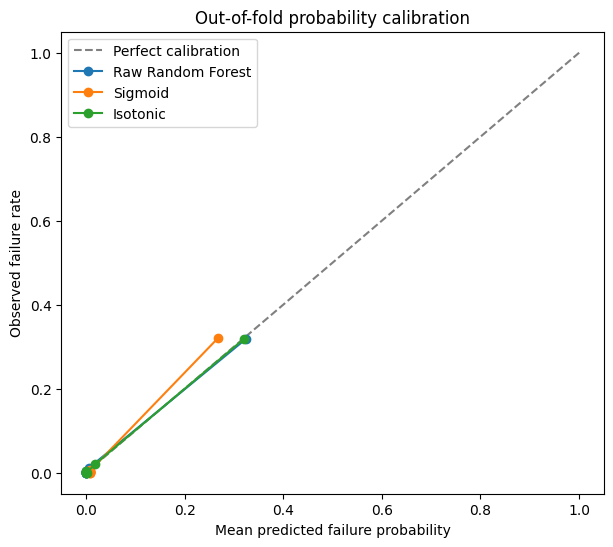

In [43]:
plt.figure(figsize=(7, 6))
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
for name, probabilities in [("Raw Random Forest", raw_oof_prob), ("Sigmoid", sigmoid_oof), ("Isotonic", isotonic_oof)]:
    observed, predicted = calibration_curve(y_train_array, probabilities, n_bins=10, strategy="quantile")
    plt.plot(predicted, observed, marker="o", label=name)
plt.xlabel("Mean predicted failure probability"); plt.ylabel("Observed failure rate")
plt.title("Out-of-fold probability calibration"); plt.legend()
plt.savefig("outputs/oof_calibration_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### 12.4 Calibration comparison table: training decision and test confirmation

The two calibrators are refitted on all training out-of-fold probabilities and applied to the test probabilities. The combined table shows the training results (which made the decision) and the test results (reported only).

**What to look for:** on the test set isotonic calibration has a marginally lower Brier score (0.00783 vs 0.00793, a difference of 0.0001), but it again lowers PR-AUC (0.888 vs 0.898). Changing the method based on test results would mean choosing with the test set, so the training-data decision stands: raw Random Forest probabilities are used from here on.

In [44]:
# Train each calibrator on all training probabilities, then apply it to the test probabilities
sigmoid_test_prob = (LogisticRegression(random_state=42).fit(raw_oof_prob.reshape(-1, 1), y_train_array)
                     .predict_proba(raw_test_prob.reshape(-1, 1))[:, 1])
isotonic_test_prob = IsotonicRegression(out_of_bounds="clip").fit(raw_oof_prob, y_train_array).predict(raw_test_prob)

test_calibration_results = pd.DataFrame([calibration_metrics("Raw Random Forest", raw_test_prob, y_test),
                                         calibration_metrics("Sigmoid", sigmoid_test_prob, y_test),
                                         calibration_metrics("Isotonic", isotonic_test_prob, y_test)])

# Training results (used for the decision) and test results (check only) in one table
calibration_table = pd.concat([calibration_results.assign(Data="Training (decision)"),
                               test_calibration_results.assign(Data="Test (check only)")], ignore_index=True)
calibration_table = calibration_table[["Data", "Method", "Brier Score", "Log Loss", "ECE", "ROC-AUC", "PR-AUC"]]
display(calibration_table.round(5))
calibration_table.to_csv("outputs/calibration_comparison.csv", index=False)

# Raw probabilities are kept (lowest training Brier score)
final_test_predictions["RF_Raw_Failure_Probability"] = raw_test_prob
print(f"\nProbabilities used from here on: raw Random Forest (test Brier score {brier_score_loss(y_test, raw_test_prob):.5f})")

,Data,Method,Brier Score,Log Loss,ECE,ROC-AUC,PR-AUC
0,Training (decision),Raw Random Forest,0.00845,0.03818,0.00396,0.97505,0.88554
1,Training (decision),Sigmoid,0.00875,0.04301,0.00307,0.97355,0.88243
2,Training (decision),Isotonic,0.00853,0.04087,0.00145,0.96819,0.87149
3,Test (check only),Raw Random Forest,0.00793,0.03589,0.00692,0.98378,0.89847
4,Test (check only),Sigmoid,0.00804,0.03923,0.00626,0.98378,0.89847
5,Test (check only),Isotonic,0.00783,0.03480,0.00364,0.98189,0.88779



Probabilities used from here on: raw Random Forest (test Brier score 0.00793)


## 13. Bootstrap Uncertainty Quantification

**Purpose:** a single test-set score can be misleading, especially with only 68 failures in the test set. Bootstrap resampling shows how much each result could vary.

The 2,000 test rows are resampled with replacement 2,000 times, and the key metrics are recalculated each time using the training-derived threshold of 0.42. The 2.5th and 97.5th percentiles of these results give a 95% confidence interval for each metric.

The point estimates are accuracy 0.992, precision 0.933, recall 0.824, F1 0.875, ROC-AUC 0.984, PR-AUC 0.898 and Brier score 0.008. The intervals are widest for recall, precision and PR-AUC, because these depend on the small number of failures.

### 13.1 Final model results at the 0.42 threshold

The tuned Random Forest's raw test-set probabilities are turned into decisions at the threshold chosen on training data (0.42). These are the point estimates that the bootstrap will put intervals around.

In [45]:
final_threshold = oof_best_f1_threshold          # 0.42, chosen on training data
final_prob = np.asarray(raw_test_prob)          # raw Random Forest probabilities (no calibration)
final_actual = np.asarray(y_test)

def calculate_final_metrics(actual, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(actual, predictions).ravel()
    return {"Accuracy": accuracy_score(actual, predictions),
            "Precision": precision_score(actual, predictions, zero_division=0),
            "Recall": recall_score(actual, predictions, zero_division=0),
            "Specificity": tn / (tn + fp),
            "F1-score": f1_score(actual, predictions, zero_division=0),
            "ROC-AUC": roc_auc_score(actual, probabilities),
            "PR-AUC": average_precision_score(actual, probabilities),
            "Brier Score": brier_score_loss(actual, probabilities)}

point_estimates = calculate_final_metrics(final_actual, final_prob, final_threshold)
tn, fp, fn, tp = confusion_matrix(final_actual, (final_prob >= final_threshold).astype(int)).ravel()
print(f"Final model: tuned Random Forest | threshold {final_threshold:.2f} | {len(final_actual)} test rows, {int(final_actual.sum())} failures")
print(f"Failures found: {tp}, missed: {fn}, false alarms: {fp}, correct non-failures: {tn}")

Final model: tuned Random Forest | threshold 0.42 | 2000 test rows, 68 failures
Failures found: 56, missed: 12, false alarms: 4, correct non-failures: 1928


### 13.2 Bootstrap 95% confidence intervals

Each of the 2,000 bootstrap samples draws 2,000 test rows at random, with replacement, so some rows appear more than once and others not at all. The metrics are recalculated on every sample, and the middle 95% of the results forms the confidence interval.

**What to look for:** accuracy and specificity are very stable (intervals under 0.01 wide), because they are dominated by the 1,932 non-failures. Recall ranges from 0.726 to 0.913: with only 68 failures, finding or missing a handful of them moves recall noticeably. This is why results for the failure class should always be read with their uncertainty.

In [46]:
rng = np.random.default_rng(seed=42)
n_bootstrap, n_rows = 2000, len(final_actual)

bootstrap_metrics = []
for _ in range(n_bootstrap):
    idx = rng.choice(np.arange(n_rows), size=n_rows, replace=True)   # resample test rows with replacement
    if len(np.unique(final_actual[idx])) < 2:                          # skip a sample with no failures (very rare)
        continue
    bootstrap_metrics.append(calculate_final_metrics(final_actual[idx], final_prob[idx], final_threshold))
bootstrap_df = pd.DataFrame(bootstrap_metrics)

confidence_interval_df = pd.DataFrame({
    "Metric": list(point_estimates),
    "Estimate": list(point_estimates.values()),
    "95% CI lower": [np.percentile(bootstrap_df[m], 2.5) for m in point_estimates],
    "95% CI upper": [np.percentile(bootstrap_df[m], 97.5) for m in point_estimates],
})
confidence_interval_df["CI width"] = confidence_interval_df["95% CI upper"] - confidence_interval_df["95% CI lower"]
confidence_interval_df["Estimate (95% CI)"] = [f"{e:.3f} ({l:.3f}–{u:.3f})" for e, l, u in
    zip(confidence_interval_df["Estimate"], confidence_interval_df["95% CI lower"], confidence_interval_df["95% CI upper"])]

print(f"Valid bootstrap samples: {len(bootstrap_df)}\n")
display(confidence_interval_df.round(5))
confidence_interval_df.to_csv("outputs/bootstrap_confidence_intervals.csv", index=False)

Valid bootstrap samples: 2000



,Metric,Estimate,95% CI lower,95% CI upper,CI width,Estimate (95% CI)
0,Accuracy,0.99200,0.98750,0.99600,0.00850,0.992 (0.988–0.996)
1,Precision,0.93333,0.86360,0.98462,0.12102,0.933 (0.864–0.985)
2,Recall,0.82353,0.72578,0.91306,0.18728,0.824 (0.726–0.913)
3,Specificity,0.99793,0.99584,0.99949,0.00365,0.998 (0.996–0.999)
4,F1-score,0.87500,0.80597,0.93220,0.12623,0.875 (0.806–0.932)
5,ROC-AUC,0.98378,0.96738,0.99585,0.02847,0.984 (0.967–0.996)
6,PR-AUC,0.89847,0.83363,0.95016,0.11653,0.898 (0.834–0.950)
7,Brier Score,0.00793,0.00492,0.01120,0.00627,0.008 (0.005–0.011)


## 14. SHAP Model Explainability

**Purpose:** to show *how* the final Random Forest uses the eight allowed predictors, so a maintenance engineer can see why a machine is ranked as high risk rather than just receiving a score.

SHAP values are calculated for every test machine, for the failure class, using the model's preprocessed inputs. The analysis covers:
- **Global importance:** which features matter most overall. Rotational speed, tool wear, temperature difference and power dominate.
- **Direction of effect:** whether higher feature values push predicted risk up or down.
- **Local explanations:** the main reasons behind the highest-risk machines.
- **Strongest driver per machine:** used later in the maintenance queue and dashboard.

SHAP values describe the model's behaviour, not physical cause and effect. They provide transparency without claiming more than the model can show.

### 14.1 Calculate SHAP values

The fitted preprocessing step converts the test data into the exact inputs the Random Forest uses: seven scaled numeric features plus two product-type columns (Type_L, Type_M). TreeExplainer then calculates, for every machine and feature, how much that feature pushed the predicted failure probability up or down.

In [47]:
try:
    import shap
except ImportError:
    !pip -q install shap
    import shap

rf_preprocessor = best_rf_model.named_steps["preprocessor"]
rf_classifier = best_rf_model.named_steps["classifier"]

# SHAP works on the model's actual inputs: scaled numbers and one-hot product type
feature_names = [name.replace("numeric__", "").replace("categorical__", "") for name in rf_preprocessor.get_feature_names_out()]
X_test_shap_df = pd.DataFrame(rf_preprocessor.transform(X_test), columns=feature_names, index=X_test.index)

shap_output = shap.TreeExplainer(rf_classifier).shap_values(X_test_shap_df)
# Keep the explanation for the failure class (the output format differs between SHAP versions)
if isinstance(shap_output, list):
    shap_values_failure = shap_output[1]
elif shap_output.ndim == 3:
    shap_values_failure = shap_output[:, :, 1]
else:
    shap_values_failure = shap_output

print("Features explained:", feature_names)
print("SHAP values shape:", shap_values_failure.shape)

Features explained: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Temperature difference [K]', 'Power [W]', 'Type_L', 'Type_M']
SHAP values shape: (2000, 9)


### 14.2 Global feature importance

The average absolute SHAP value shows how strongly each feature influences predictions overall, also expressed as a share of the total. The bar chart shows the same ranking. The summary plot adds direction: each dot is one machine, its colour is the feature value (red = high, blue = low), and its position shows whether it pushed risk up (right) or down (left).

**What to look for:** rotational speed (25.2%), tool wear (23.4%), temperature difference (21.0%) and power (20.1%) together account for about 90% of the model's attribution. Product type and the raw temperatures matter very little.

,Feature,Mean Absolute SHAP,Relative Importance (%)
0,Rotational speed [rpm],0.0235,25.2109
1,Tool wear [min],0.0218,23.3685
2,Temperature difference [K],0.0196,21.0023
3,Power [W],0.0187,20.0873
4,Torque [Nm],0.0056,6.0342
5,Type_L,0.0015,1.5634
6,Process temperature [K],0.0013,1.4276
7,Air temperature [K],0.0009,0.9765
8,Type_M,0.0003,0.3292



Top 4 features: 89.67% of the total


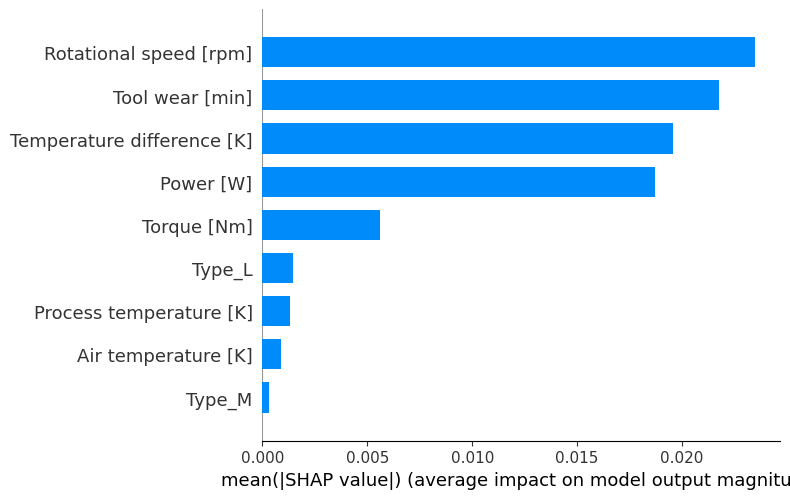

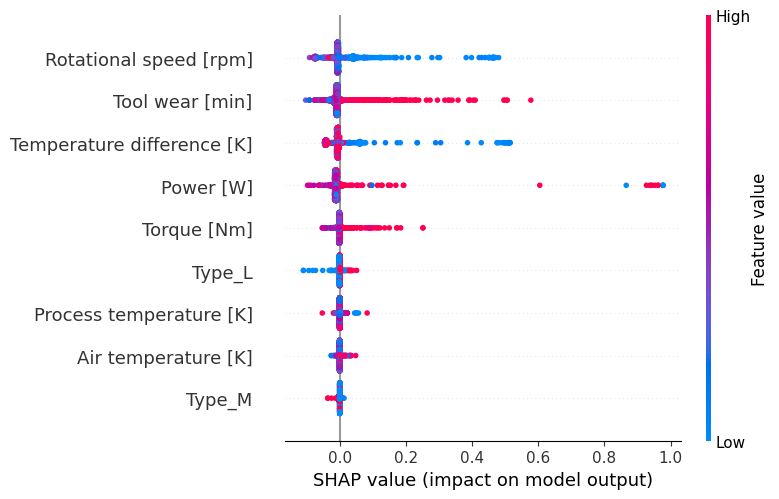

In [48]:
importance = np.abs(shap_values_failure).mean(axis=0)
global_shap_importance = pd.DataFrame({"Feature": feature_names, "Mean Absolute SHAP": importance,
                                       "Relative Importance (%)": importance / importance.sum() * 100})
global_shap_importance = global_shap_importance.sort_values("Mean Absolute SHAP", ascending=False).reset_index(drop=True)
display(global_shap_importance.round(4))
global_shap_importance.to_csv("outputs/global_shap_feature_importance.csv", index=False)
print(f"\nTop 4 features: {global_shap_importance['Relative Importance (%)'].head(4).sum():.2f}% of the total")

# Bar chart (importance) and dot chart (importance + direction)
for kind in ["bar", "dot"]:
    shap.summary_plot(shap_values_failure, X_test_shap_df, plot_type=kind, show=False)
    plt.savefig(f"outputs/shap_{kind}_plot.png", dpi=150, bbox_inches="tight")
    plt.show()

### 14.3 Highest-risk machines and their main drivers

The ten test machines with the highest predicted failure probability are listed with their key operating conditions; all ten actually failed. For the top five, the two strongest SHAP drivers show *why* each one was flagged.

**What we can find:** different machines are flagged for different reasons. Four of the top five are driven by a small temperature difference combined with low rotational speed, a heat-dissipation pattern. Machine L54191 is driven almost entirely by power: it runs very fast with very low torque, giving unusually low power. The model does not treat every failure the same way.

In [49]:
top_10 = np.argsort(-raw_test_prob)[:10]          # the 10 test machines with the highest risk
top_high_risk = analysis_df.loc[X_test.index[top_10], ["Product ID", "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]",
                                                        "Temperature difference [K]", "Power [W]", "Machine failure"]].copy()
top_high_risk["Failure probability"] = raw_test_prob[top_10]
display(top_high_risk.round(2))

print("\nMain SHAP drivers of the top 5 machines:")
for pos in top_10[:5]:
    shap_row = pd.Series(shap_values_failure[pos], index=feature_names)
    top2 = shap_row[shap_row.abs().sort_values(ascending=False).index[:2]]
    print(analysis_df.loc[X_test.index[pos], "Product ID"], "->", ", ".join(f"{f} ({v:+.3f})" for f, v in top2.items()))

,Product ID,Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperature difference [K],Power [W],Machine failure,Failure probability
1391,L48571,2737,8.8,142,11.3,2522.24,1,1.0
4307,L51487,1259,63.9,20,8.5,8424.71,1,1.0
4270,L51450,1331,52.0,154,8.3,7247.86,1,1.0
4618,M19478,1335,53.6,164,8.3,7493.33,1,1.0
7997,M22857,2710,9.7,143,11.2,2752.77,1,1.0
3814,M18674,1326,59.1,88,8.5,8206.53,1,1.0
8245,M23105,1303,68.6,111,11.3,9360.46,1,1.0
2444,L49624,1267,68.2,76,9.4,9048.77,1,1.0
4258,M19118,1297,60.7,125,8.4,8244.37,1,1.0
5706,L52886,1290,70.0,139,9.5,9456.19,1,1.0



Main SHAP drivers of the top 5 machines:
L48571 -> Power [W] (+0.977), Tool wear [min] (-0.007)
L51487 -> Temperature difference [K] (+0.498), Rotational speed [rpm] (+0.452)
L51450 -> Temperature difference [K] (+0.513), Rotational speed [rpm] (+0.464)
M19478 -> Temperature difference [K] (+0.513), Rotational speed [rpm] (+0.464)
M22857 -> Power [W] (+0.977), Tool wear [min] (-0.006)


### 14.4 Direction of effect

For each feature, the correlation between its value and its SHAP value shows the general direction of its effect: positive means higher values raise predicted risk, negative means they lower it.

**What we can find:** higher tool wear and torque raise predicted risk. Higher rotational speed and a larger temperature difference lower it, so a small process–air temperature gap is a warning sign. Power has a weak overall correlation because its effect is non-linear: both unusually low and unusually high power can be linked to failure.

In [50]:
# Positive correlation: higher value -> higher risk; negative: higher value -> lower risk
corr = [np.corrcoef(X_test_shap_df[f], shap_values_failure[:, i])[0, 1] for i, f in enumerate(feature_names)]
direction = pd.DataFrame({"Feature": feature_names, "Correlation": corr}).set_index("Feature")
direction["Effect"] = np.select([direction["Correlation"] >= 0.2, direction["Correlation"] <= -0.2],
                                ["Higher value -> higher risk", "Higher value -> lower risk"], "Weak / non-linear")
display(direction.loc[global_shap_importance["Feature"]].round(4))

,Correlation,Effect
Feature,,
Rotational speed [rpm],-0.2766,Higher value -> lower risk
Tool wear [min],0.4145,Higher value -> higher risk
Temperature difference [K],-0.3410,Higher value -> lower risk
Power [W],0.0860,Weak / non-linear
Torque [Nm],0.3684,Higher value -> higher risk
Type_L,0.2443,Higher value -> higher risk
Process temperature [K],-0.0250,Weak / non-linear
Air temperature [K],0.1888,Weak / non-linear
Type_M,-0.1963,Weak / non-linear


### 14.5 Strongest risk driver for every machine

For each of the 2,000 test machines, the feature with the largest SHAP value is stored as its "strongest risk driver". This gives the maintenance queue and dashboard a short, readable reason next to each machine's risk score.

In [51]:
strongest = np.abs(shap_values_failure).argmax(axis=1)
final_test_predictions["Strongest_Risk_Driver"] = np.array(feature_names)[strongest]
final_test_predictions["Strongest_Driver_SHAP"] = shap_values_failure[np.arange(len(strongest)), strongest]
print("Strongest risk driver saved for", len(final_test_predictions), "test machines")

Strongest risk driver saved for 2000 test machines


## 15. Maintenance Priority Framework and Fixed Inspection Capacity

**Purpose:** to turn the final failure probabilities into an ordered list a maintenance team can act on.

Every test machine gets a 0–100 risk score, a maintenance rank (1 = inspect first), a priority group, a recommended action and its strongest SHAP risk driver. The priority groups use the two thresholds chosen on training data:
- **High:** probability of 0.42 or more
- **Medium:** probability from 0.05 up to 0.42
- **Low:** probability below 0.05

Of the 2,000 test machines, 60 are High priority and 93 Medium, containing 56 and 8 of the 68 failures. The remaining 1,847 Low-priority machines contain only 4 failures.

The ranking is then tested against fixed inspection budgets: if the team can only inspect the top 5%, 10% or 20% of machines, how many real failures does it find? This answers the second research question. The actual outcomes are kept alongside the ranking for validation only. In real use they would not be known at decision time.

### 15.1 Build the ranked maintenance list

Each test machine receives its failure probability, a 0–100 risk score, a priority group, a recommended action and its main SHAP driver. Machines are then sorted from highest to lowest risk and numbered, so rank 1 is the first machine to inspect.

In [52]:
HIGH_PRIORITY_THRESHOLD = oof_best_f1_threshold        # 0.42 (best F1 on training data)
MEDIUM_PRIORITY_THRESHOLD = oof_high_recall_threshold  # 0.05 (recall >= 90% on training data)

def assign_priority(p):
    if p >= HIGH_PRIORITY_THRESHOLD:
        return "High"
    if p >= MEDIUM_PRIORITY_THRESHOLD:
        return "Medium"
    return "Low"

actions = {"High": "Immediate inspection / maintenance review",
           "Medium": "Increase monitoring and schedule inspection",
           "Low": "Continue routine monitoring"}

# One row per test machine, in the same order as X_test
maintenance_priority_df = analysis_df.loc[X_test.index, ["UDI", "Product ID", "Type"] + numeric_features + ["Machine failure"]].copy()
maintenance_priority_df["Failure Probability"] = raw_test_prob
maintenance_priority_df["Maintenance Risk Score"] = raw_test_prob * 100
maintenance_priority_df["Maintenance Priority"] = maintenance_priority_df["Failure Probability"].apply(assign_priority)
maintenance_priority_df["Recommended Action"] = maintenance_priority_df["Maintenance Priority"].map(actions)
maintenance_priority_df["Primary Risk Driver"] = final_test_predictions["Strongest_Risk_Driver"].values
maintenance_priority_df["Primary Driver SHAP"] = final_test_predictions["Strongest_Driver_SHAP"].values
maintenance_priority_df["Driver Effect"] = np.where(maintenance_priority_df["Primary Driver SHAP"] > 0,
                                                    "Increases predicted risk", "Reduces predicted risk")

# Rank machines from highest to lowest risk (rank 1 = inspect first)
maintenance_priority_df = maintenance_priority_df.sort_values(["Failure Probability", "Maintenance Risk Score"], ascending=[False, False])
maintenance_priority_df.insert(0, "Maintenance Rank", np.arange(1, len(maintenance_priority_df) + 1))

print(f"High: probability >= {HIGH_PRIORITY_THRESHOLD:.2f} | Medium: {MEDIUM_PRIORITY_THRESHOLD:.2f} to {HIGH_PRIORITY_THRESHOLD:.2f} | Low: below {MEDIUM_PRIORITY_THRESHOLD:.2f}")
print(f"Risk score across all {len(maintenance_priority_df)} machines: average {maintenance_priority_df['Maintenance Risk Score'].mean():.2f}, highest {maintenance_priority_df['Maintenance Risk Score'].max():.0f}")
display(maintenance_priority_df[["Maintenance Rank", "Product ID", "Type", "Maintenance Risk Score", "Maintenance Priority",
                                 "Primary Risk Driver", "Recommended Action", "Machine failure"]].head(10).round(2))

High: probability >= 0.42 | Medium: 0.05 to 0.42 | Low: below 0.05
Risk score across all 2000 machines: average 3.45, highest 100


,Maintenance Rank,Product ID,Type,Maintenance Risk Score,Maintenance Priority,Primary Risk Driver,Recommended Action,Machine failure
1391,1,L48571,L,100.0,High,Power [W],Immediate inspection / maintenance review,1
8582,2,M23442,M,100.0,High,Power [W],Immediate inspection / maintenance review,1
2444,3,L49624,L,100.0,High,Power [W],Immediate inspection / maintenance review,1
3814,4,M18674,M,100.0,High,Temperature difference [K],Immediate inspection / maintenance review,1
5706,5,L52886,L,100.0,High,Power [W],Immediate inspection / maintenance review,1
4270,6,L51450,L,100.0,High,Temperature difference [K],Immediate inspection / maintenance review,1
4307,7,L51487,L,100.0,High,Temperature difference [K],Immediate inspection / maintenance review,1
380,8,L47560,L,100.0,High,Power [W],Immediate inspection / maintenance review,1
7997,9,M22857,M,100.0,High,Power [W],Immediate inspection / maintenance review,1
7011,10,L54191,L,100.0,High,Power [W],Immediate inspection / maintenance review,1


### 15.2 Priority groups and failure capture

For each priority group: how many machines it contains, how many actually failed, what share of all failures it holds, and the failure rate within the group.

**What to look for:** the High group is only 3% of machines but holds 82% of all failures, and 93% of its machines really failed. High and Medium together (153 machines, 7.65% of the test set) contain 64 of the 68 failures. The Low group (92% of machines) has a failure rate of just 0.22%.

In [53]:
order = ["High", "Medium", "Low"]
total_failures = maintenance_priority_df["Machine failure"].sum()

priority_summary = maintenance_priority_df.groupby("Maintenance Priority").agg(
    Cases=("UDI", "count"), Failures=("Machine failure", "sum"), Mean_Risk_Score=("Maintenance Risk Score", "mean")).reindex(order)
priority_summary["Share of cases (%)"] = priority_summary["Cases"] / len(maintenance_priority_df) * 100
priority_summary["Share of all failures (%)"] = priority_summary["Failures"] / total_failures * 100
priority_summary["Failure rate in group (%)"] = priority_summary["Failures"] / priority_summary["Cases"] * 100
display(priority_summary.round(2))
priority_summary.to_csv("outputs/priority_group_summary.csv")

high_medium = priority_summary.loc[["High", "Medium"]].sum()
print(f"\nHigh + Medium together: {int(high_medium['Cases'])} cases ({high_medium['Cases'] / 20:.2f}% of the test set) "
      f"containing {int(high_medium['Failures'])} of {int(total_failures)} failures ({high_medium['Failures'] / total_failures:.2%})")

,Cases,Failures,Mean_Risk_Score,Share of cases (%),Share of all failures (%),Failure rate in group (%)
Maintenance Priority,,,,,,
High,60,56,88.37,3.00,82.35,93.33
Medium,93,8,13.61,4.65,11.76,8.60
Low,1847,4,0.18,92.35,5.88,0.22



High + Medium together: 153 cases (7.65% of the test set) containing 64 of 68 failures (94.12%)


### 15.3 What drives the High-priority machines, and which product types they are

The strongest SHAP driver is counted across the 60 High-priority machines, giving each flagged machine a short, reviewable reason instead of an unexplained score. The product-type table checks that priority is not limited to one product category.

**What to look for:** temperature difference is the most common reason (40%), followed by tool wear (27%) and power (22%). High-priority machines come from all three product types (33 L, 22 M, 5 H).

In [54]:
high_priority_df = maintenance_priority_df[maintenance_priority_df["Maintenance Priority"] == "High"]

drivers = high_priority_df["Primary Risk Driver"].value_counts().to_frame("High-priority machines")
drivers["Share (%)"] = drivers["High-priority machines"] / len(high_priority_df) * 100
print("Main SHAP driver among the", len(high_priority_df), "High-priority machines")
display(drivers.round(2))

print("\nProduct type by priority group")
display(pd.crosstab(maintenance_priority_df["Type"], maintenance_priority_df["Maintenance Priority"])[order])

Main SHAP driver among the 60 High-priority machines


,High-priority machines,Share (%)
Primary Risk Driver,,
Temperature difference [K],24,40.00
Tool wear [min],16,26.67
Power [W],13,21.67
Rotational speed [rpm],5,8.33
Torque [Nm],2,3.33



Product type by priority group


Maintenance Priority,High,Medium,Low
Type,,,
H,5,11,198
L,33,54,1083
M,22,28,566


### 15.4 Fixed inspection capacity (5%, 10%, 20%)

Real maintenance teams have a fixed budget. Here the ranked list is cut at exactly the top 100, 200 and 400 machines (5%, 10% and 20% of the test set), and the real failures inside each cut are counted:
- **Capture:** share of all 68 failures that were found
- **Precision:** share of inspected machines that really failed
- **Lift:** how many times better than inspecting machines at random (precision ÷ the 3.40% failure rate)
- **Extra inspections:** healthy machines inspected; **Missed failures:** failures outside the budget

**What to look for:** inspecting just the top 100 machines finds 59 of 68 failures (86.8%), 17 times better than random. The top 200 find 65 (95.6%). Doubling the budget to 400 finds no extra failures and only adds 200 unnecessary inspections. The capture curve shows the model's ranking rising far above random inspection.

Test set: 2000 machines, 68 failures (prevalence 3.40%)



,Budget,Cases inspected,Failures found,Capture (%),Precision (%),Lift,Extra inspections,Missed failures
0,5%,100,59,86.76,59.00,17.35,41,9
1,10%,200,65,95.59,32.50,9.56,135,3
2,20%,400,65,95.59,16.25,4.78,335,3


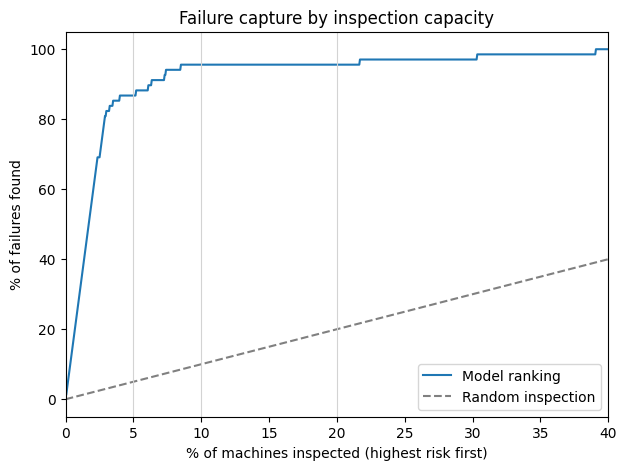

In [55]:
ranked = maintenance_priority_df.reset_index(drop=True)          # already sorted by Maintenance Rank
total_cases = len(ranked)
prevalence = total_failures / total_cases

capacity_rows = []
for share in [0.05, 0.10, 0.20]:
    k = int(total_cases * share)                       # number of machines the team can inspect
    found = int(ranked["Machine failure"].head(k).sum())
    capacity_rows.append({"Budget": f"{share:.0%}", "Cases inspected": k, "Failures found": found,
                          "Capture (%)": found / total_failures * 100, "Precision (%)": found / k * 100,
                          "Lift": (found / k) / prevalence, "Extra inspections": k - found,
                          "Missed failures": int(total_failures) - found})
fixed_capacity_results = pd.DataFrame(capacity_rows)

print(f"Test set: {total_cases} machines, {int(total_failures)} failures (prevalence {prevalence:.2%})\n")
display(fixed_capacity_results.round(2))
fixed_capacity_results.to_csv("outputs/fixed_inspection_capacity_results.csv", index=False)

# Capture curve: share of failures found vs share of machines inspected
inspected = np.arange(1, total_cases + 1) / total_cases * 100
found_share = ranked["Machine failure"].cumsum() / total_failures * 100
plt.figure(figsize=(7, 5))
plt.plot(inspected, found_share, label="Model ranking")
plt.plot([0, 100], [0, 100], "--", color="grey", label="Random inspection")
for x in [5, 10, 20]:
    plt.axvline(x, color="lightgrey", linewidth=0.8)
plt.xlim(0, 40); plt.xlabel("% of machines inspected (highest risk first)"); plt.ylabel("% of failures found")
plt.title("Failure capture by inspection capacity"); plt.legend()
plt.savefig("outputs/capacity_capture_curve.png", dpi=150, bbox_inches="tight")
plt.show()

### 15.5 Save the maintenance datasets

Two files are saved for the dashboard and for checking. The dashboard dataset holds what a maintenance manager would see: rank, risk, priority, action, driver and operating conditions. The validation dataset adds the actual outcome, which in real use would only be known later.

In [56]:
dashboard_columns = ["Maintenance Rank", "UDI", "Product ID", "Type", "Failure Probability", "Maintenance Risk Score",
                     "Maintenance Priority", "Recommended Action", "Primary Risk Driver", "Driver Effect"] + numeric_features
maintenance_priority_df[dashboard_columns].to_csv("outputs/maintenance_dashboard_dataset.csv", index=False)
maintenance_priority_df[["Maintenance Rank", "UDI", "Product ID", "Failure Probability",
                         "Maintenance Priority", "Machine failure"]].to_csv("outputs/maintenance_priority_validation.csv", index=False)
print("Saved: maintenance_dashboard_dataset.csv, maintenance_priority_validation.csv")

Saved: maintenance_dashboard_dataset.csv, maintenance_priority_validation.csv


## 16. Interactive Maintenance Dashboard

**Purpose:** to present the results as a simple decision-support view for a maintenance manager. The dashboard does not make predictions itself. It reads the ranked maintenance list from the previous step and answers practical questions:

1. **How big is the problem?** Key numbers (KPIs) for the 2,000 machines.
2. **How many machines need attention?** Machines per priority group.
3. **Why are they flagged?** The main SHAP driver behind High-priority machines.
4. **Where are the risky machines?** A risk map of rotational speed vs torque.
5. **How quickly does risk drop?** Failure probability across the ranking.
6. **What if we can only inspect a fixed number?** Failures found at 5%, 10% and 20% capacity.
7. **Which machines first?** The maintenance queue with rank, risk score, driver and recommended action.

The charts are interactive: hovering shows machine details. Everything is also saved as one HTML file that opens in any web browser. The dashboard supports a human decision; it does not schedule repairs automatically and is not connected to live sensors.

### 16.1 Key numbers (KPIs)

A one-table summary of the maintenance situation: the size of each priority group, the average and highest risk score, and how many real failures would be found with a fixed inspection budget. The budget figures use the actual test outcomes, so they serve as validation of the ranking.

In [57]:

dash = maintenance_priority_df.copy()               # ranked list from Step 15 (rank 1 = highest risk)
order = ["High", "Medium", "Low"]
colors = {"High": "#d62728", "Medium": "#ff7f0e", "Low": "#2ca02c"}
counts = dash["Maintenance Priority"].value_counts().reindex(order)
cap = fixed_capacity_results.set_index("Budget")

kpis = pd.DataFrame({
    "KPI": ["Machines assessed", "High priority", "Medium priority", "Low priority", "High + Medium watchlist",
            "Average risk score (0-100)", "Highest risk score",
            "Failures found if top 5% inspected", "Failures found if top 10% inspected"],
    "Value": [len(dash), counts["High"], counts["Medium"], counts["Low"], counts["High"] + counts["Medium"],
              f"{dash['Maintenance Risk Score'].mean():.2f}", f"{dash['Maintenance Risk Score'].max():.0f}",
              f"{cap.loc['5%', 'Failures found']} of 68 ({cap.loc['5%', 'Capture (%)']:.1f}%)",
              f"{cap.loc['10%', 'Failures found']} of 68 ({cap.loc['10%', 'Capture (%)']:.1f}%)"]})
display(kpis)

,KPI,Value
0,Machines assessed,2000
1,High priority,60
2,Medium priority,93
3,Low priority,1847
4,High + Medium watchlist,153
5,Average risk score (0-100),3.45
6,Highest risk score,100
7,Failures found if top 5% inspected,59 of 68 (86.8%)
8,Failures found if top 10% inspected,65 of 68 (95.6%)


### 16.2 Dashboard charts

Five interactive charts:
- **Machines per priority group:** most machines are Low priority, and only a small group needs action.
- **Main risk drivers among High-priority machines:** the SHAP reason behind each flagged machine.
- **Risk map:** each dot is a machine plotted by rotational speed and torque, coloured by priority. High-risk machines cluster at the extremes (low speed with high torque, or very high speed with very low torque).
- **Risk curve:** failure probability drops sharply after the first few dozen machines and then stays near zero, so risk is concentrated in a short list. Dashed lines mark the High (0.42) and Medium (0.05) thresholds.
- **Inspection budget:** failures found when only the top 5%, 10% or 20% of machines are inspected.

In [58]:
# 1. Machines per priority group
fig_priority = px.bar(x=order, y=counts.values, color=order, color_discrete_map=colors, text=counts.values,
                      labels={"x": "Maintenance priority", "y": "Machines"}, title="Machines per maintenance priority")

# 2. Main SHAP driver among High-priority machines
drivers = dash.loc[dash["Maintenance Priority"] == "High", "Primary Risk Driver"].value_counts()
fig_drivers = px.bar(x=drivers.values, y=drivers.index, orientation="h", text=drivers.values,
                     labels={"x": "High-priority machines", "y": "Main risk driver"},
                     title="Why are High-priority machines flagged? (main SHAP driver)")
fig_drivers.update_layout(yaxis={"categoryorder": "total ascending"})

# 3. Risk map: rotational speed vs torque, coloured by priority
fig_map = px.scatter(dash, x="Rotational speed [rpm]", y="Torque [Nm]", color="Maintenance Priority",
                     color_discrete_map=colors, category_orders={"Maintenance Priority": order}, opacity=0.7,
                     hover_data=["Product ID", "Maintenance Risk Score", "Primary Risk Driver"],
                     title="Machine risk map: rotational speed vs torque")

# 4. Failure probability along the ranking, with the two thresholds
fig_curve = px.line(dash, x="Maintenance Rank", y="Failure Probability",
                    title="Predicted failure probability across the maintenance ranking")
fig_curve.add_hline(y=HIGH_PRIORITY_THRESHOLD, line_dash="dash", line_color="#d62728", annotation_text="High (0.42)")
fig_curve.add_hline(y=MEDIUM_PRIORITY_THRESHOLD, line_dash="dot", line_color="#ff7f0e", annotation_text="Medium (0.05)")

# 5. Failures found at each fixed inspection budget
fig_capacity = px.bar(fixed_capacity_results, x="Budget", y="Failures found", text="Failures found",
                      labels={"Budget": "Inspection budget (top % of machines)"},
                      title="Failures found with a fixed inspection budget (68 failures in total)")

for fig in [fig_priority, fig_drivers, fig_map, fig_curve, fig_capacity]:
    fig.show()

### 16.3 Maintenance queue

The working list a maintenance manager would use: the 50 highest-risk machines with their rank, risk score, priority, main SHAP driver and recommended action. The actual failure outcome is deliberately **not** shown, because in real use it would not be known when the decision is made.

In [59]:
queue = dash.head(50)[["Maintenance Rank", "Product ID", "Type", "Maintenance Risk Score",
                       "Maintenance Priority", "Primary Risk Driver", "Recommended Action"]].round(1)
fig_queue = go.Figure(go.Table(
    header=dict(values=list(queue.columns), fill_color="#1f4e78", font=dict(color="white"), align="left"),
    cells=dict(values=[queue[col] for col in queue.columns], align="left")))
fig_queue.update_layout(title="Maintenance queue: top 50 machines", height=600)
fig_queue.show()

### 16.4 Save the dashboard

All KPIs, charts and the queue are saved together as one HTML file. It works offline and can be opened in any web browser or shared with others.

In [60]:
figures = [fig_priority, fig_drivers, fig_map, fig_curve, fig_capacity, fig_queue]

with open("outputs/maintenance_dashboard.html", "w") as f:
    f.write("<h1>Maintenance Prioritisation Dashboard</h1>")
    f.write("<p>AI4I 2020 test set: 2,000 machines ranked by predicted failure risk (tuned Random Forest). "
            "Decision support only; final decisions remain with maintenance staff.</p>")
    f.write("<h2>Key numbers</h2>" + kpis.to_html(index=False))
    for i, fig in enumerate(figures):
        f.write(fig.to_html(full_html=False, include_plotlyjs=(i == 0)))

print("Dashboard saved: outputs/maintenance_dashboard.html")

Dashboard saved: outputs/maintenance_dashboard.html


## 17. Software Environment

The exact library versions used for this run are printed and saved as `requirements.txt`, so the analysis can be reproduced with the same software.

In [62]:
import sys, sklearn, xgboost, shap, plotly, matplotlib, kagglehub

versions = {"numpy": np.__version__, "pandas": pd.__version__, "scikit-learn": sklearn.__version__,
            "xgboost": xgboost.__version__, "shap": shap.__version__, "plotly": plotly.__version__,
            "matplotlib": matplotlib.__version__, "kagglehub": getattr(kagglehub, "__version__", "")}

print("Python", sys.version.split()[0])
with open("requirements.txt", "w") as f:
    for name, version in versions.items():
        line = f"{name}=={version}" if version else name
        print(line)
        f.write(line + "\n")
print("\nSaved: requirements.txt")

Python 3.13.16
numpy==2.1.3
pandas==2.2.3
scikit-learn==1.6.1
xgboost==3.4.1
shap==0.52.0
plotly==5.24.1
matplotlib==3.10.0
kagglehub==1.0.2

Saved: requirements.txt
